# 06 — Patrones exploratorios: qué se mueve con el triage total y en qué episodios

## Qué contesta este cuaderno

El objetivo del proyecto es anticipar cuándo sube el conteo de triages de urgencias del SES Hospital Universitario de Caldas, y explicar por qué sube. Antes de modelar conviene saber qué factores externos se mueven junto con ese conteo, en qué momentos concretos lo hacen y qué diseño de análisis es capaz de verlos. El cuaderno responde en dos tiempos.

1. **Una mirada amplia con un método de promedios** (secciones 1 a 5): la serie con su historia, lo que el calendario no explica, un mapa de correlaciones con rezago contra 23 variables externas y una prueba de cuánto efecto necesita ese mapa para detectar algo.
2. **Los mismos factores leídos por episodio** (secciones 6 a 11): la Feria de Manizales, la mitad del año, diciembre y el arranque de enero, los picos, el clima como transición y las catástrofes. Cada factor se lee con cuatro preguntas: su **reloj** (en cuánto tiempo actúa), su **gatillo** (qué cambia: un cambio brusco o un nivel), su **condición** (cuándo actúa: día laboral, festivo, temporada) y su **subgrupo** (hora, edad, asegurador en que se nota).

## Cómo leerlo

Todo es exploratorio: sirve para generar hipótesis, no para confirmarlas. Una asociación que aparece aquí solo se convierte en predictor cuando se fija de antemano y se prueba fuera de muestra, con origen rodante, contra el control de calendario. El conteo total de un hospital con ruido diario de ±12 % esconde los efectos que viven en un subgrupo o en pocos días, así que la ausencia de señal en el total no se lee como ausencia de efecto: la sección 4 mide qué tamaño de efecto habría podido ver el mapa, y las secciones 6 a 10 repiten la medición con la ventana y el subgrupo propios de cada factor.

## De dónde salen los datos

Todo son agregados versionados en el repositorio. El cuaderno no se conecta a ninguna base y no maneja datos de pacientes.

| Dato | Archivo | Fuente |
|---|---|---|
| Triage diario del SES Hospital Universitario de Caldas | `salidas/triage_diario.parquet` | base del hospital, agregado por día |
| Triage por hora, por banda de edad y por asegurador | `salidas/triage_horario.parquet`, `triage_edad.parquet`, `triage_entidad.parquet` | base del hospital, agregados; el asegurador se agrupa con una clasificación de nombres de entidades |
| Festivos, puentes, vacaciones del calendario general | `calendarios/calendario_Colombia.csv` | calendario oficial |
| Receso escolar de mitad de año, con fechas oficiales de cada año | `calendarios/calendario_escolar_manizales.csv` | resoluciones de la Secretaría de Educación de Manizales y del Ministerio de Educación |
| Clima diario | `calendarios/clima_unificado.csv.gz` | IDEAM, METAR, Open-Meteo y NASA POWER; los días en que el pluviómetro de La Nubia reporta cero de forma sostenida mientras el satélite registra lluvia (199 días) se tratan como ausentes, y solo el 34,7 % de los días tiene pluviómetro válido (`calendarios/docs/CLIMA.md`) |
| Vigilancia semanal de Manizales | `calendarios/vigilancia_sivigila*.csv.gz` | microdatos SIVIGILA, INS |
| Consultas por institución | `calendarios/vigilancia_sivigila_instituciones.csv.gz` | SIVIGILA, evento 995 |
| Lesiones personales por día en la ciudad | `calendarios/seguridad_mindefensa.csv.gz` | Policía Nacional, publicadas por el Ministerio de Defensa en datos.gov.co |
| Eventos y desastres | `calendarios/eventos_manizales_2020_2026.csv`, `calendarios/desastres_manizales_2020_2026.csv` | calendarios manuales con la fuente de cada evento |

El hospital en el SIVIGILA es el código `170010010301` (Servicios Especiales de Salud). Se excluye de las consultas de la ciudad para que la variable externa no contenga al propio hospital.


In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "CLAUDE.md").exists())
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.dates as mdates

# Paleta de referencia (dataviz): categoricos en orden fijo, divergente azul-gris-rojo.
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUPERFICIE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
DIVERGENTE = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", ROJO])
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUDO,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA,
    "font.size": 10, "lines.linewidth": 1.6, "legend.frameon": False,
})

FIN = "2026-09-20"      # el 21 esta incompleto
SES = 170010010301      # el hospital en SIVIGILA

# ---------- triage diario. Un dia SIN filas en el total no es "cero consultas": es una caida
# del registro (el hospital nunca cierra urgencias). Queda como nulo, no como cero.
d = pd.read_parquet(RAIZ / "salidas" / "triage_diario.parquet")
d["dia"] = pd.to_datetime(d["dia"])
tri = d.set_index("dia")["triages"].asfreq("D").loc[:FIN].astype(float)

# ---------- calendario
CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad",
       "es_temporada_fin_anio", "es_regreso_colegio"]
cal = (pd.read_csv(RAIZ / "calendarios" / "calendario_Colombia.csv", parse_dates=["fecha"])
         .set_index("fecha")[CAL + ["dia_semana"]].apply(pd.to_numeric, errors="coerce").fillna(0))

# ---------- clima
clima = pd.read_csv(RAIZ / "calendarios" / "clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")

# ---------- vigilancia (todos los archivos de series; el de instituciones aparte)
series = [pd.read_csv(p) for p in sorted((RAIZ / "calendarios").glob("vigilancia_sivigila*.csv.gz"))
          if "instituciones" not in p.name]
cols = ["evento", "fecha_inicio_semana", "ambito", "variable", "valor"]
vig = pd.concat([s[cols] for s in series if set(cols) <= set(s.columns)], ignore_index=True)
vig["fecha_inicio_semana"] = pd.to_datetime(vig["fecha_inicio_semana"])
inst = pd.read_csv(RAIZ / "calendarios" / "vigilancia_sivigila_instituciones.csv.gz",
                   parse_dates=["fecha_inicio_semana"])

eventos = pd.read_csv(RAIZ / "calendarios" / "eventos_manizales_2020_2026.csv")
desastres = pd.read_csv(RAIZ / "calendarios" / "desastres_manizales_2020_2026.csv")

print(f"triage: {tri.index.min():%Y-%m-%d} a {tri.index.max():%Y-%m-%d}, {int(tri.sum()):,} triages")
print(f"clima hasta {clima.index.max():%Y-%m-%d}; vigilancia {vig.fecha_inicio_semana.min():%Y} a "
      f"{vig.fecha_inicio_semana.max():%Y-%m-%d}; eventos SIVIGILA: {sorted(vig.evento.unique())}")


triage: 2020-01-01 a 2026-09-20, 433,298 triages
clima hasta 2026-08-28; vigilancia 2011 a 2025-12-28; eventos SIVIGILA: [113, 155, 300, 346, 348, 349, 356, 360, 365, 370, 380, 390, 400, 410, 412, 414, 452, 549, 620, 810, 813, 820, 825, 831, 850, 875, 995, 998]


In [2]:
# ---------- herramientas comunes
def semana_epi(s, como="sum"):
    """Agrega a semana epidemiologica (domingo a sabado) indexada por el domingo."""
    r = s.resample("W-SAT")
    out = getattr(r, como)()
    n = s.resample("W-SAT").count()
    out.index = out.index - pd.Timedelta(days=6)
    n.index = out.index
    return out, n

def ols_residuo(y, Z):
    Z = Z.astype(float)
    b, *_ = np.linalg.lstsq(Z.values, y.values, rcond=None)
    return pd.Series(y.values - Z.values @ b, index=y.index)

def efectos_anio(idx):
    return pd.get_dummies(pd.Index(idx.year, name="a"), prefix="a", drop_first=True).set_index(idx).astype(float)

def armonicos(idx, k=3):
    t = idx.dayofyear.values / 365.25
    return pd.DataFrame({f"{f}{h}": fn(2 * np.pi * h * t) for h in range(1, k + 1)
                         for f, fn in (("s", np.sin), ("c", np.cos))}, index=idx)

COVID = ("2020-03-15", "2022-02-28")   # fuera del ajuste; se muestra, no se modela

# ---------- residuo DIARIO: log(triages) sin calendario y sin el nivel de cada anio
D = pd.DataFrame({"n": tri}).join(cal)
D = D[(D.n > 0)]
ajuste = ~D.index.to_series().between(*COVID)
Zd = pd.concat([pd.get_dummies(D["dia_semana"].astype(int), prefix="dow", drop_first=True).astype(float),
                D[CAL], efectos_anio(D.index)], axis=1)
Zd.insert(0, "c", 1.0)
b, *_ = np.linalg.lstsq(Zd[ajuste].values.astype(float), np.log(D.n[ajuste]).values, rcond=None)
D["res"] = np.log(D.n) - Zd.values.astype(float) @ b          # residuo en log ~ % sobre lo esperado

# Caidas de registro: dias sin filas, o con menos del 40 % de lo esperado. Se excluyen.
sin_filas = tri.index[tri.isna()]
caidos = D.index[(D.res < np.log(0.40)) & ~D.index.to_series().between(*COVID)]   # en COVID la caida fue real
print("dias sin ninguna fila:", [f"{x:%Y-%m-%d}" for x in sin_filas])
print("dias con < 40 % de lo esperado (probable caida parcial):",
      {f"{x:%Y-%m-%d}": int(D.n[x]) for x in caidos})
tri_limpio = tri.copy(); tri_limpio[caidos] = np.nan
D = D.drop(caidos)
print(f"residuo diario (fuera de COVID): sd {D.res[~D.index.to_series().between(*COVID)].std():.3f}")

# ---------- residuo SEMANAL (solo semanas con los 7 dias validos)
tw, nd = semana_epi(tri_limpio)
tw = tw[nd == 7]
cw, _ = semana_epi(cal[CAL])
W = pd.DataFrame({"triage": tw}).join(cw)
W = W.loc["2022-03-06":FIN]
Zw = pd.concat([W[CAL], efectos_anio(W.index)], axis=1); Zw.insert(0, "c", 1.0)
W["res"] = ols_residuo(np.log(W.triage), Zw)                  # sin calendario ni nivel del anio
Zws = pd.concat([Zw, armonicos(W.index)], axis=1)
W["res_sin_estac"] = ols_residuo(np.log(W.triage), Zws)       # ademas, sin estacionalidad anual
print(f"{len(W)} semanas completas; sd residuo {W.res.std():.3f} "
      f"(sin estacionalidad {W.res_sin_estac.std():.3f})")


dias sin ninguna fila: ['2024-03-19', '2024-03-20']
dias con < 40 % de lo esperado (probable caida parcial): {'2024-03-21': 40}
residuo diario (fuera de COVID): sd 0.121


236 semanas completas; sd residuo 0.082 (sin estacionalidad 0.071)


---
# 1. La serie con su historia al lado

Media de triages por día en cada semana epidemiológica, 2020-2026, con los hechos de Manizales y del sistema de salud que están documentados en los calendarios del proyecto.

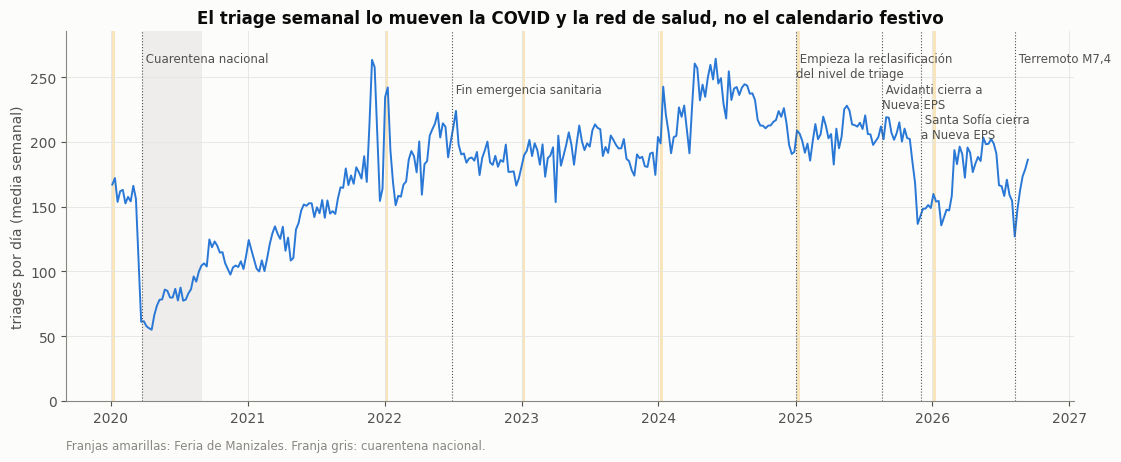

triages por día, media de cada año (días con dato):
dia
2020    105.7
2021    149.3
2022    189.6
2023    192.4
2024    226.9
2025    199.6
2026    172.6
2020, media diaria: enero 164.1, febrero 156.2, abril 58.6


In [3]:
media_sem = (tw / 7)
hitos = [  # (fecha, texto, desplazamiento vertical)
    ("2020-03-25", "Cuarentena nacional", 0), ("2022-06-30", "Fin emergencia sanitaria", 1),
    ("2025-01-01", "Empieza la reclasificación\ndel nivel de triage", 0),
    ("2025-08-21", "Avidanti cierra a\nNueva EPS", 1), ("2025-12-01", "Santa Sofía cierra\na Nueva EPS", 2),
    ("2026-08-10", "Terremoto M7,4", 0)]
fig, ax = plt.subplots(figsize=(13, 4.8))
ferias = eventos[eventos.nombre_evento.eq("Feria de Manizales") & eventos.estado.eq("realizado")]
for _, r in ferias.iterrows():
    ax.axvspan(pd.Timestamp(r.fecha_inicio), pd.Timestamp(r.fecha_fin), color=AMARILLO, alpha=.25, lw=0)
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-08-31"), color=MUDO, alpha=.12, lw=0)
ax.plot(media_sem.index, media_sem.values, color=AZUL, lw=1.4)
ymax = media_sem.max()
for f, t, k in hitos:
    x = pd.Timestamp(f)
    ax.axvline(x, color=TINTA2, lw=.8, ls=":")
    ax.text(x, ymax * (1.02 - .09 * k), " " + t, fontsize=8.5, color=TINTA2, va="top")
ax.set_ylabel("triages por día (media semanal)")
ax.set_title("El triage semanal lo mueven la COVID y la red de salud, no el calendario festivo")
ax.text(0, -.13, "Franjas amarillas: Feria de Manizales. Franja gris: cuarentena nacional.",
        transform=ax.transAxes, fontsize=8.5, color=MUDO)
ax.set_ylim(0, ymax * 1.08)
plt.show()
print("triages por día, media de cada año (días con dato):")
print(tri_limpio.groupby(tri_limpio.index.year).mean().round(1).to_string())
m20 = tri_limpio.loc["2020"].groupby(tri_limpio.loc["2020"].index.month).mean().round(1)
print(f"2020, media diaria: enero {m20[1]}, febrero {m20[2]}, abril {m20[4]}")


## Lectura

**Los movimientos más grandes de la serie no son del clima ni de las fiestas: son de la COVID y de la red de salud.**

| 2020 | 2021 | 2022 | 2023 | 2024 | 2025 | 2026 |
|---|---|---|---|---|---|---|
| 105,7 | 149,3 | 189,6 | 192,4 | **226,9** | 199,6 | 172,6 |

Triages por día, media de cada año sobre los días con dato (el 2026 llega al 20 de septiembre).

- **La cuarentena** hunde la serie: la media diaria de 2020 es de 164,1 en enero y 156,2 en febrero, y de 58,6 en abril. La recuperación es lenta y la serie tarda hasta 2022 en superar el nivel previo a la pandemia.
- **La caída desde 2024** es de 226,9 a 199,6 en 2025 y a 172,6 en 2026. La reclasificación del nivel de triage que empieza en 2025 es un fenómeno distinto: cambiar la etiqueta de un triage no cambia el conteo. El cuaderno 07 localiza la caída del volumen en una sola aseguradora, Nueva EPS, que pasa de 115,8 a 72,2 triages por día entre 2025 y 2026.
- **Desde mediados de noviembre de 2025** las semanas quedan entre −15 y −32 % por debajo de lo esperado (sección 2). El descenso empieza antes del cierre de Santa Sofía a Nueva EPS, el 1 de diciembre. La coincidencia en el tiempo no prueba que una cosa cause la otra, pero es un tipo de hecho que ningún calendario externo registraba.
- **El terremoto** del 10 de agosto de 2026 se ve como un pozo de dos semanas; la sección 11 lo mide.
- **Cada Feria** cae en la primera quincena de enero, sobre el regreso de las vacaciones. A simple vista no se distingue de ese regreso.

**Tratamiento de los datos.** El 19 y el 20 de marzo de 2024 no tienen ningún registro, y el 21 tiene 40. Es una caída del sistema de registro, no un día sin pacientes, porque urgencias no cierra. Esos días se tratan como sin dato, no como cero; contarlos como cero fabricaría una semana artificialmente baja.

**Límite.** La figura es la media semanal y no ve lo que ocurre dentro de la semana.

---
# 2. Lo que el calendario no explica

Residuo semanal: cuánto se aparta cada semana de lo que esperaría el calendario (festivos, puentes, vacaciones, Semana Santa, Navidad) **dentro de su propio año**. Es lo que una variable externa tendría que explicar. Se marcan las semanas que quedan fuera de ±2 desviaciones.

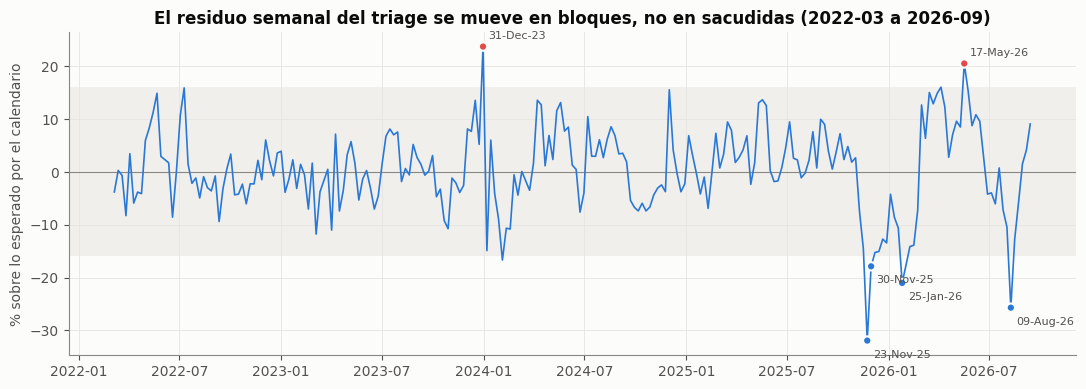

sd del residuo semanal: 8.0 %   ·   autocorrelación a 1 semana: +0.62


,% sobre lo esperado,qué pasaba (calendarios)
dia,,
2023-12-31,23.6,Feria de Manizales; Alumbrado Navideno Aguinal...
2026-05-17,20.4,1 festivo(s)
2026-04-05,15.9,Semana Santa
2022-07-10,15.8,Fiesta Virgen del Carmen; Fin emergencia sanit...
2024-12-01,15.4,Dia de las Velitas; Media Maraton de Manizales...
2026-05-24,15.2,—
2026-03-15,14.9,—
2022-05-22,14.8,—
2026-03-29,14.7,Semana Santa; 2 festivo(s)


In [4]:
r = W["res"]
pct = (np.exp(r) - 1) * 100
sd = pct.std()
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.axhspan(-2 * sd, 2 * sd, color="#f0efec", lw=0)
ax.axhline(0, color=MUDO, lw=.8)
ax.plot(pct.index, pct.values, color=AZUL, lw=1.2)
extremos = pct[pct.abs() > 2 * sd]
extremos = extremos.reindex(extremos.abs().sort_values(ascending=False).index[:6])
ax.scatter(extremos.index, extremos.values, s=36, color=[ROJO if v > 0 else AZUL for v in extremos],
           edgecolor=SUPERFICIE, lw=1.5, zorder=3)
for x, v in extremos.items():
    ax.annotate(f"{x:%d-%b-%y}", (x, v), textcoords="offset points", xytext=(4, 6 if v > 0 else -12),
                fontsize=8, color=TINTA2)
ax.set_ylabel("% sobre lo esperado por el calendario")
ax.set_title("El residuo semanal del triage se mueve en bloques, no en sacudidas (2022-03 a 2026-09)")
plt.show()

def que_paso(sem):
    fin = sem + pd.Timedelta(days=6)
    txt = []
    for _, e in eventos.dropna(subset=["fecha_inicio"]).iterrows():
        a, b_ = pd.Timestamp(e.fecha_inicio), pd.Timestamp(e.fecha_fin if pd.notna(e.fecha_fin) else e.fecha_inicio)
        if a <= fin and b_ >= sem: txt.append(e.nombre_evento)
    for _, e in desastres.iterrows():
        a, b_ = pd.Timestamp(e.fecha_inicio), pd.Timestamp(e.fecha_fin)
        if a <= fin and b_ >= sem and (b_ - a).days <= 14: txt.append(f"{e.tipo_evento} ({e.municipio})")
    for f, t, _ in hitos:
        if sem - pd.Timedelta(days=21) <= pd.Timestamp(f) <= fin: txt.append(t.replace("\n", " "))
    fest = int(W.loc[sem, "es_festivo"]) if sem in W.index else 0
    if fest: txt.append(f"{fest} festivo(s)")
    return "; ".join(dict.fromkeys(txt)) or "—"

tabla = pd.DataFrame({"% sobre lo esperado": pct.round(1)})
orden = pd.concat([tabla.nlargest(10, "% sobre lo esperado"), tabla.nsmallest(10, "% sobre lo esperado")])
orden["qué pasaba (calendarios)"] = [que_paso(i) for i in orden.index]
orden.index = orden.index.strftime("%Y-%m-%d")
print(f"sd del residuo semanal: {sd:.1f} %   ·   autocorrelación a 1 semana: {r.autocorr():+.2f}")
orden


## Lectura

**Lo que el calendario no explica es un 8,0 % semanal, y no es ruido: viene en bloques.**

- **La autocorrelación del residuo a una semana es de +0,62.** Si una semana va por encima de lo esperado, la que sigue suele ir igual. Lo que queda sin explicar se mueve despacio, en semanas o meses seguidos, y no en sacudidas de un día. Eso apunta a variables que cambian de nivel poco a poco, como la red de servicios, la afiliación o una temporada, más que a eventos de un día.
- **Las semanas extremas se agrupan.** De las 10 más bajas, 7 caen entre noviembre de 2025 y febrero de 2026 y otra es la del terremoto. Hay además un bloque alto de marzo a mayo de 2026, con semanas de +15 a +20 %.
- **La columna «qué pasaba» sale vacía en 8 de las 20 semanas extremas, y en otras 2 solo trae un festivo.** Los calendarios externos que se usan hoy no tienen nada que decir de la mayoría de ellas. El hueco de información no está en el clima sino en lo que le ocurre a la red de salud de Manizales.
- **La semana más alta (31 de diciembre de 2023, +23,6 %)** junta Año Nuevo, el regreso de las vacaciones y los primeros días de la Feria de 2024. Puede ser un efecto real o un control de fin de año mal ajustado; con estos datos no se distingue.

**Límite.** El residuo quita el nivel de cada año, por eso la caída de 2025 frente a 2024 no aparece aquí sino en la figura de la sección 1. Lo que se ve es lo que se mueve dentro de cada año.

---
# 3. Mapa de correlaciones con rezago

Cada línea del mapa es una variable externa y cada columna indica cuántas semanas **antes** del triage se mide (0 es la misma semana; −1 es la semana *posterior*, que sirve de control: una variable que «predice» hacia atrás en el tiempo comparte otra cosa con el triage, no lo causa).

Dos paneles: **(a)** residuo dentro de cada año, con la estacionalidad; **(b)** quitando además la estacionalidad anual de ambas series. El punto negro marca los |r| por encima del umbral aproximado de significación, corregido por autocorrelación (Bartlett).

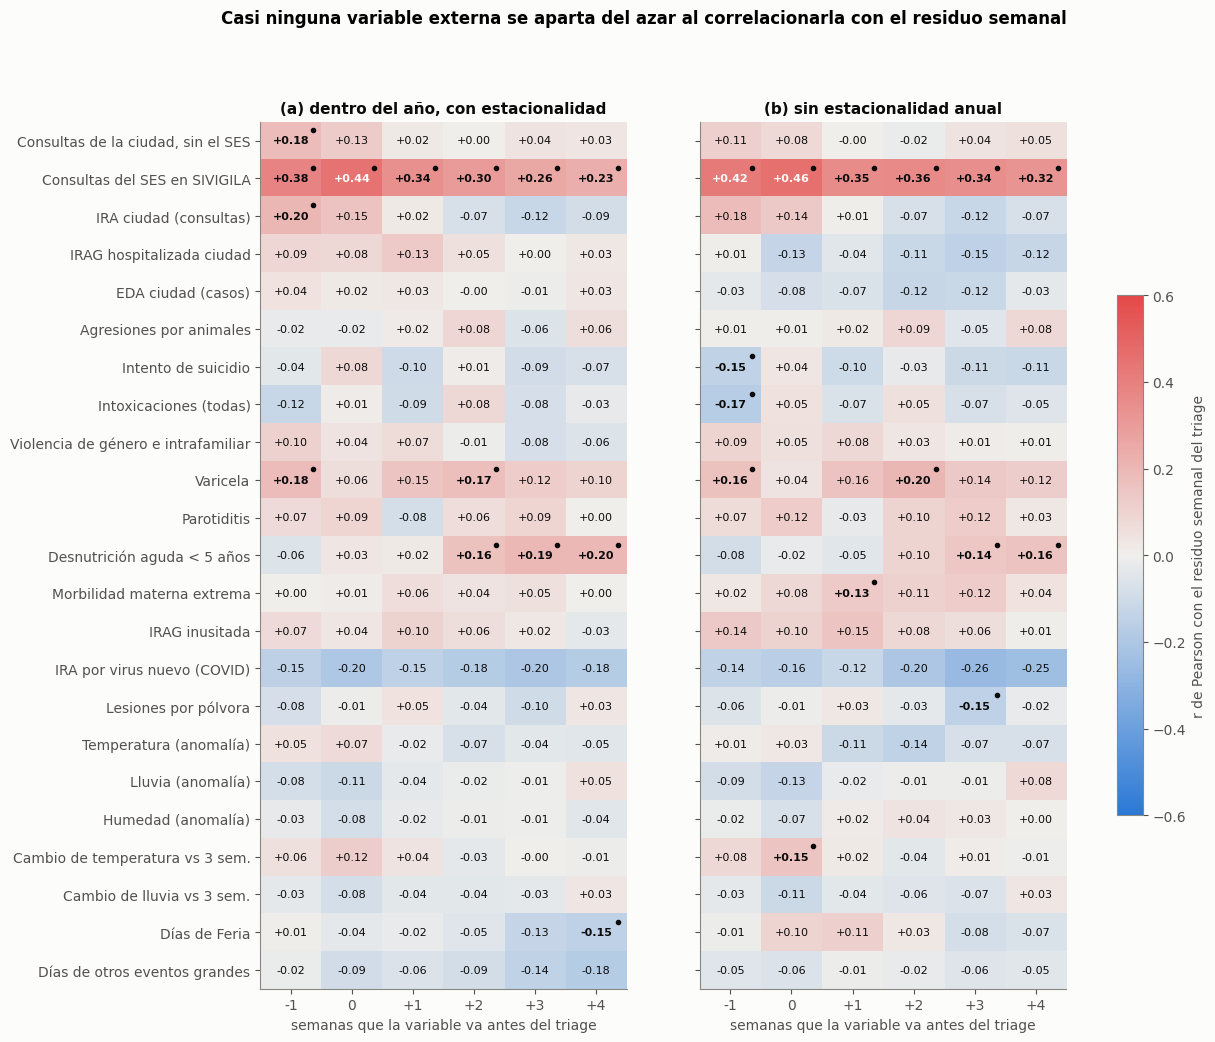

(a): 14 celdas marcadas de 138 pruebas; por azar se esperarian ~7
(b): 15 celdas marcadas de 138 pruebas; por azar se esperarian ~7
marcadas en (b): [('Consultas del SES en SIVIGILA', -1, 0.42), ('Consultas del SES en SIVIGILA', 0, 0.46), ('Consultas del SES en SIVIGILA', 1, 0.35), ('Consultas del SES en SIVIGILA', 2, 0.36), ('Consultas del SES en SIVIGILA', 3, 0.34), ('Consultas del SES en SIVIGILA', 4, 0.32), ('Intento de suicidio', -1, -0.15), ('Intoxicaciones (todas)', -1, -0.17), ('Varicela', -1, 0.16), ('Varicela', 2, 0.2), ('Desnutrición aguda < 5 años', 3, 0.14), ('Desnutrición aguda < 5 años', 4, 0.16), ('Morbilidad materna extrema', 1, 0.13), ('Lesiones por pólvora', 3, -0.15), ('Cambio de temperatura vs 3 sem.', 0, 0.15)]
semanas con dato por variable:
Consultas de la ciudad, sin el SES     199
Consultas del SES en SIVIGILA          198
IRA ciudad (consultas)                 199
IRAG hospitalizada ciudad              199
EDA ciudad (casos)                     199
Agresiones 

In [5]:
# ---------- variables externas semanales
ext = pd.DataFrame(index=W.index)

man = vig[vig.ambito.eq("manizales")].pivot_table(index="fecha_inicio_semana",
                                                  columns=["evento", "variable"], values="valor", aggfunc="sum")
def serie_vig(ev, var):
    return man[(ev, var)] if (ev, var) in man.columns else None

ciudad = inst[inst.cod_upgd.ne(SES)].groupby("fecha_inicio_semana")["consultas_todas_causas"].sum()
ext["Consultas de la ciudad, sin el SES"] = np.log(ciudad.replace(0, np.nan))
ext["Consultas del SES en SIVIGILA"] = np.log(inst[inst.cod_upgd.eq(SES)].groupby("fecha_inicio_semana")
                                              ["consultas_todas_causas"].sum().replace(0, np.nan))
ext["IRA ciudad (consultas)"] = np.log(serie_vig(995, "consultas_ira_total"))
ext["IRAG hospitalizada ciudad"] = np.log1p(serie_vig(995, "hospitalizaciones_irag_total"))
ext["EDA ciudad (casos)"] = np.log(serie_vig(998, "casos_eda_total"))
# otros eventos SIVIGILA (casos ocurridos en Manizales). Solo los que pueden llegar a una
# urgencia; quedan fuera cancer (155), tuberculosis (810-825), VIH (850) y las intoxicaciones
# por tipo (360-414), que ya estan sumadas en el 365.
NOMBRES = {300: "Agresiones por animales", 356: "Intento de suicidio", 365: "Intoxicaciones (todas)",
           875: "Violencia de género e intrafamiliar", 831: "Varicela", 620: "Parotiditis",
           113: "Desnutrición aguda < 5 años", 549: "Morbilidad materna extrema",
           348: "IRAG inusitada", 346: "IRA por virus nuevo (COVID)", 452: "Lesiones por pólvora"}
for ev, nombre in NOMBRES.items():
    s = serie_vig(ev, "casos_ocurrencia")
    if s is not None and s.sum() > 0:
        ext[nombre] = np.log1p(s)

# clima: anomalia contra el mismo mes, y cambio contra las 3 semanas previas
cl = pd.DataFrame({"t": semana_epi(clima["temp_media_consenso"], "mean")[0],
                   "p": semana_epi(clima["precip_consenso_mm"], "sum")[0],
                   "h": semana_epi(clima["humedad_consenso"], "mean")[0]})
z = cl.groupby(cl.index.month).transform(lambda s: (s - s.mean()) / s.std())
ext["Temperatura (anomalía)"] = z.t
ext["Lluvia (anomalía)"] = z.p
ext["Humedad (anomalía)"] = z.h
ext["Cambio de temperatura vs 3 sem."] = z.t - z.t.shift(1).rolling(3).mean()
ext["Cambio de lluvia vs 3 sem."] = z.p - z.p.shift(1).rolling(3).mean()

# eventos sociales (dias por semana)
def dias_de(filtro):
    s = pd.Series(0.0, index=pd.date_range("2020-01-01", FIN))
    for _, e in eventos[filtro].dropna(subset=["fecha_inicio"]).iterrows():
        s.loc[e.fecha_inicio: (e.fecha_fin if pd.notna(e.fecha_fin) else e.fecha_inicio)] = 1
    return semana_epi(s)[0]
ok = eventos.estado.isin(["realizado", "hibrido"])
ext["Días de Feria"] = dias_de(ok & eventos.nombre_evento.eq("Feria de Manizales"))
ext["Días de otros eventos grandes"] = dias_de(ok & ~eventos.nombre_evento.eq("Feria de Manizales")
                                               & eventos.categoria.isin(["teatro", "musical", "civico", "taurino", "deportivo"]))
ext = ext.loc[W.index.min():]

# ---------- quitar el nivel de cada anio (y en (b) tambien la estacionalidad) a cada variable
def limpiar(s, estac):
    s = s.dropna()
    if s.std() == 0 or len(s) < 30: return s * np.nan
    Z = pd.concat([cw.reindex(s.index).fillna(0), efectos_anio(s.index)], axis=1); Z.insert(0, "c", 1.0)
    if estac: Z = pd.concat([Z, armonicos(s.index)], axis=1)
    return ols_residuo(s, Z)

LAGS = [-1, 0, 1, 2, 3, 4]
def mapa(estac):
    y = W["res_sin_estac" if estac else "res"]
    R, S = pd.DataFrame(index=ext.columns, columns=LAGS, dtype=float), pd.DataFrame(index=ext.columns, columns=LAGS, dtype=bool)
    for c in ext.columns:
        x = limpiar(ext[c], estac)
        for L in LAGS:
            par = pd.concat([y, x.shift(L)], axis=1).dropna()
            if len(par) < 30: continue
            r_ = par.iloc[:, 0].corr(par.iloc[:, 1])
            a1, a2 = par.iloc[:, 0].autocorr(), par.iloc[:, 1].autocorr()
            neff = len(par) * (1 - a1 * a2) / (1 + a1 * a2)
            R.loc[c, L], S.loc[c, L] = r_, abs(r_) > 1.96 / np.sqrt(max(neff - 3, 4))
    return R, S

(Ra, Sa), (Rb, Sb) = mapa(False), mapa(True)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.42 * len(ext.columns) + 1.6), sharey=True)
for ax, R, S, t in [(axes[0], Ra, Sa, "(a) dentro del año, con estacionalidad"),
                    (axes[1], Rb, Sb, "(b) sin estacionalidad anual")]:
    im = ax.imshow(R.values.astype(float), cmap=DIVERGENTE, vmin=-.6, vmax=.6, aspect="auto")
    ax.set_xticks(range(len(LAGS)), [f"{L:+d}" if L else "0" for L in LAGS])
    ax.set_yticks(range(len(R)), R.index)
    ax.set_xlabel("semanas que la variable va antes del triage")
    ax.set_title(t, fontsize=11); ax.grid(False)
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            v = R.iat[i, j]
            if pd.isna(v): continue
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=8,
                    color=TINTA if abs(v) < .4 else SUPERFICIE, fontweight="bold" if S.iat[i, j] else "normal")
            if S.iat[i, j]:
                ax.plot(j + .36, i - .28, "o", ms=3, color=TINTA)
fig.colorbar(im, ax=axes, shrink=.6, label="r de Pearson con el residuo semanal del triage")
fig.suptitle("Casi ninguna variable externa se aparta del azar al correlacionarla con el residuo semanal", fontweight="bold", x=.42)
plt.show()
for nom, S_ in [("(a)", Sa), ("(b)", Sb)]:
    k_ = int(S_.values.sum()); n_ = int(Ra.notna().values.sum())
    print(f"{nom}: {k_} celdas marcadas de {n_} pruebas; por azar se esperarian ~{0.05*n_:.0f}")
print("marcadas en (b):", [(i, c, round(Rb.loc[i, c], 2)) for i in Rb.index for c in LAGS if Sb.loc[i, c]])
n_par = pd.concat([W.res, ext], axis=1).notna().sum()
print("semanas con dato por variable:\n" + n_par.drop("res").to_string())

filas_ver = ["Consultas de la ciudad, sin el SES", "Temperatura (anomalía)", "Lluvia (anomalía)", "Humedad (anomalía)",
             "Cambio de temperatura vs 3 sem.", "Cambio de lluvia vs 3 sem.", "Días de Feria", "Días de otros eventos grandes",
             "Varicela", "Desnutrición aguda < 5 años", "IRA por virus nuevo (COVID)"]
print("r en (a), filas escogidas (rezagos -1 a 4):"); print(Ra.loc[filas_ver].round(2).to_string())
print("r en (b), filas escogidas:"); print(Rb.loc[filas_ver].round(2).to_string())
sin_ses = Rb.drop("Consultas del SES en SIVIGILA").drop(columns=[])
print(f"en (b), sin la fila del propio SES: {100 * (sin_ses.abs() <= .20).values[sin_ses.notna().values].mean():.0f} % de las celdas con |r| <= 0,20; "
      f"|r| máximo {sin_ses.abs().max().max():.2f}")


## Lectura

**Con este método casi nada se mueve junto con el triage total, y esa afirmación solo vale para este método.**

El mapa correlaciona un residuo al que ya se le quitó el calendario, el nivel de cada año y, en el panel (b), la estacionalidad. Es un filtro que ya se llevó parte de la señal: un efecto que se repite cada año en las mismas fechas queda absorbido por la estacionalidad, uno de pocos días se diluye en la ventana semanal, un cambio brusco no se ve en una variable de nivel, y lo que ocurre en un subgrupo se pierde en el total. Concluir «no afecta» a partir de lo que sobrevive a ese filtro sería leer solo a los sobrevivientes. La sección 4 mide qué efecto necesita el mapa para detectar algo.

Lo que el mapa sí muestra:

1. **Hay 15 celdas marcadas de 138 pruebas, y el azar daría unas 7.** Como mucho, un puñado de ellas es real y no se sabe cuáles. Excluyendo la variable del propio SES, el 97 % de las celdas del panel (b) tiene |r| de 0,20 o menos y el máximo es 0,26.
2. **El método encuentra una relación cuando existe.** Las consultas del propio SES reportadas al SIVIGILA correlacionan de +0,32 a +0,46 con su triage en todos los rezagos del panel (b). Es la misma institución: funciona como prueba de control y no como hallazgo.
3. **La demanda del resto de la ciudad apenas acompaña**: entre −0,02 y +0,11 en (b) y hasta +0,18 en (a), con los rezagos que van antes del triage cerca de cero. Se examina en la sección 5.
4. **El clima de nivel no aparece.** Ninguna variable de nivel supera |0,14| en (b). La lluvia de la misma semana da −0,13 en (b) y −0,11 en (a): más lluvia, algo menos de triage, con el mismo signo que en la sección 10. El cambio de temperatura de la misma semana da +0,15 en (b).
5. **Los eventos sociales desaparecen al quitar la estacionalidad.** En (a) los días de Feria dan −0,13 y −0,15 a 3 y 4 semanas y los de otros eventos grandes −0,14 y −0,18; en (b) esas celdas quedan en −0,08 y −0,07 (Feria) y −0,06 y −0,05 (otros eventos), y ninguna se marca; las de la misma semana y la posterior a la Feria dan +0,10 y +0,11, también sin marcar. El −0,15 de (a) refleja el bajón de febrero, posterior a la Feria (nivel de febrero de −7,2 %, sección 9), y no un efecto de ella.
6. **Tres señales débiles que solo sirven para mirar con más detalle:**
   - **Varicela**: +0,16 a +0,20 en (b), pero también en −1, con la variable *después* del triage. Eso sugiere un factor común, probablemente el calendario escolar, más que una causa.
   - **Desnutrición aguda en menores de 5 años**: +0,14 y +0,16 a 3 y 4 semanas.
   - **IRA por virus nuevo (COVID)**: de −0,12 a −0,26 en (b), pero con solo 104 semanas (2022-2023). Puede ser el final del periodo pospandemia y no un efecto.
7. **Las celdas marcadas en −1** (intento de suicidio −0,15, intoxicaciones −0,17) son sospechosas por construcción, porque la variable va después del triage.

**Límites.**
- Correlación lineal y semanal.
- El SIVIGILA llega solo hasta 2025, así que el mapa cubre 2022-2025, unas 200 semanas.
- El umbral de significación es aproximado: Bartlett, sin corrección por comparaciones múltiples.
- Correlación no es efecto: una variable externa puede moverse con el triage porque ambos dependen de una tercera.

---
# 4. Lo que el mapa podía y no podía ver

Para saber qué ausencia de señal permite concluir, se inyecta en el triage semanal un efecto conocido y se repite el proceso del mapa. El episodio inyectado es de **4 semanas**: la que contiene el 4 de enero de 2023, 2024, 2025 y 2026, que es el tamaño y el momento de una Feria. Se mide el |r| que obtiene el mapa en los paneles (a) y (b) para efectos de 2,5 a 30 % en la semana, y se compara con el umbral de significación. Aparte, se simulan 2.000 colocaciones al azar de las mismas 4 semanas, para ver con qué frecuencia se detectaría el efecto si no coincidiera con una estación.

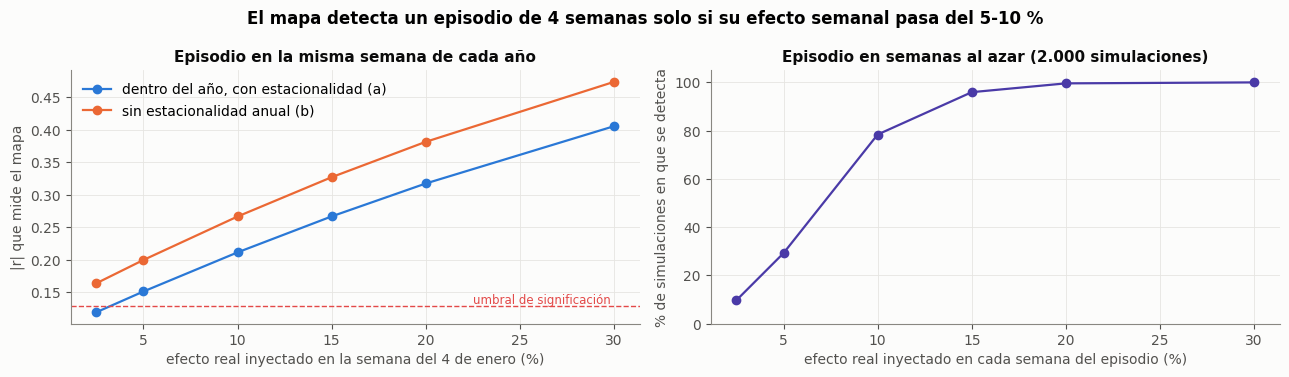

4 semanas con episodio de 236; umbral |r| = 0.128; sd del residuo semanal 0.082


,r con (a),r con (b),prob. de detectarlo (semanas al azar)
efecto en la semana (%),,,
2.5,0.119,0.164,0.098
5.0,0.151,0.199,0.292
10.0,0.211,0.266,0.784
15.0,0.267,0.327,0.960
20.0,0.317,0.381,0.996
30.0,0.405,0.474,1.000


In [6]:
# ---------- ¿podia este mapa ver un episodio de la Feria? Se inyecta un efecto conocido y se repite el proceso.
ly = np.log(W.triage)
semana_feria = pd.Series(0.0, index=W.index)
for a in range(2023, 2027):                                    # semana que contiene el 4 de enero
    ini_ = pd.Timestamp(a, 1, 4)
    semana_feria[W.index[(W.index <= ini_) & (W.index + pd.Timedelta(days=6) >= ini_)]] = 1.0
n_ep = int(semana_feria.sum())
umbral = 1.96 / np.sqrt(len(W) - 3)

filas = []
for efecto in [0.025, 0.05, 0.10, 0.15, 0.20, 0.30]:
    ly2 = ly + semana_feria * np.log(1 + efecto)
    ya, yb = ols_residuo(ly2, Zw), ols_residuo(ly2, Zws)
    xa, xb = limpiar(semana_feria, False), limpiar(semana_feria, True)
    filas.append({"efecto en la semana (%)": efecto * 100, "r con (a)": ya.corr(xa), "r con (b)": yb.corr(xb)})
P1 = pd.DataFrame(filas).set_index("efecto en la semana (%)")

# mismo ejercicio con las semanas del episodio al azar (el caso favorable: no coinciden con una estacion)
rng = np.random.default_rng(7)
yb0 = W["res_sin_estac"]
det = {}
for efecto in [0.025, 0.05, 0.10, 0.15, 0.20, 0.30]:
    ok_ = 0
    for _ in range(2000):
        x = pd.Series(0.0, index=W.index)
        x.iloc[rng.choice(len(W), n_ep, replace=False)] = 1.0
        y2 = yb0 + x * np.log(1 + efecto)
        ok_ += abs(y2.corr(x)) > umbral
    det[efecto * 100] = ok_ / 2000
P1["prob. de detectarlo (semanas al azar)"] = pd.Series(det)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax.plot(P1.index, P1["r con (a)"].abs(), "o-", color=AZUL, label="dentro del año, con estacionalidad (a)")
ax.plot(P1.index, P1["r con (b)"].abs(), "o-", color=NARANJA, label="sin estacionalidad anual (b)")
ax.axhline(umbral, color=ROJO, lw=1, ls="--"); ax.text(P1.index[-1], umbral, "umbral de significación ", color=ROJO, va="bottom", ha="right", fontsize=8.5)
ax.set_xlabel("efecto real inyectado en la semana del 4 de enero (%)"); ax.set_ylabel("|r| que mide el mapa")
ax.set_title("Episodio en la misma semana de cada año", fontsize=11); ax.legend(loc="upper left")
ax2.plot(P1.index, 100 * P1["prob. de detectarlo (semanas al azar)"], "o-", color=VIOLETA)
ax2.set_xlabel("efecto real inyectado en cada semana del episodio (%)"); ax2.set_ylabel("% de simulaciones en que se detecta")
ax2.set_title("Episodio en semanas al azar (2.000 simulaciones)", fontsize=11); ax2.set_ylim(0, 105)
fig.suptitle(f"El mapa detecta un episodio de {n_ep} semanas solo si su efecto semanal pasa del 5-10 %", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"{n_ep} semanas con episodio de {len(W)}; umbral |r| = {umbral:.3f}; sd del residuo semanal {W.res.std():.3f}")
P1.round(3)

## Lectura

**El mapa detecta un efecto semanal de 5 % o más cuando el episodio cae en la misma semana de cada año, y de 10 % o más cuando cae en semanas cualesquiera.**

| Efecto en la semana | |r| en (a) | |r| en (b) | Detección con semanas al azar |
|---|---|---|---|
| 2,5 % | 0,119 | 0,164 | 9,8 % |
| 5 % | 0,151 | 0,199 | 29,2 % |
| 10 % | 0,211 | 0,266 | 78,4 % |
| 15 % | 0,267 | 0,327 | 96,0 % |

El umbral es |r| = 0,128, con 236 semanas y un residuo semanal de 0,082 de desviación.

- **Un episodio breve necesita ser grande.** Con 4 semanas de 236, un efecto del 5 % en la semana se detecta en menos de un tercio de las colocaciones al azar. La Feria sube el total un 7,3 % en sus primeros 5 días (sección 6), es decir, un 5 % aproximadamente al repartirlo en una semana de 7 días (7,3 × 5/7): queda en el límite de lo que el mapa puede ver, y su efecto real varía de un año a otro, lo que baja todavía más la correlación.
- **Quitar la estacionalidad no borra por sí solo un episodio que cae siempre en las mismas fechas.** En esta simulación el |r| del panel (b) resulta mayor que el de (a). El mapa pierde la Feria por tamaño, por dilución en la ventana semanal y por la diferencia de efecto entre años (sección 6), más que por el tratamiento de la estacionalidad.
- **El subgrupo pesa menos de lo que parece en el total.** El SOAT es el 3,8 % del triage y la Feria lo sube 24,4 puntos más que otros regresos de vacaciones: eso aporta unos 0,9 puntos al total. Los particulares son el 0,8 % del triage y suben 32,4 puntos más: aportan 0,3. Una huella que en su subgrupo es clara es invisible en el total, y por eso las secciones 6 a 10 miran el subgrupo.

**Límite.** La simulación es favorable al mapa: supone el mismo efecto cada año, que es justo lo que no ocurre con la Feria. Tampoco evalúa los cambios bruscos, que una variable de nivel no puede representar.

---
# 5. La demanda de la ciudad frente a la del hospital

Consultas semanales por todas las causas de las demás instituciones de Manizales (SIVIGILA 995, **sin el SES**) frente al triage del hospital. Las dos series van en índice: cada semana dividida por la media de su año, para compararlas en el mismo eje sin que el crecimiento de la red (instituciones que entran a notificar) se lleve la figura.

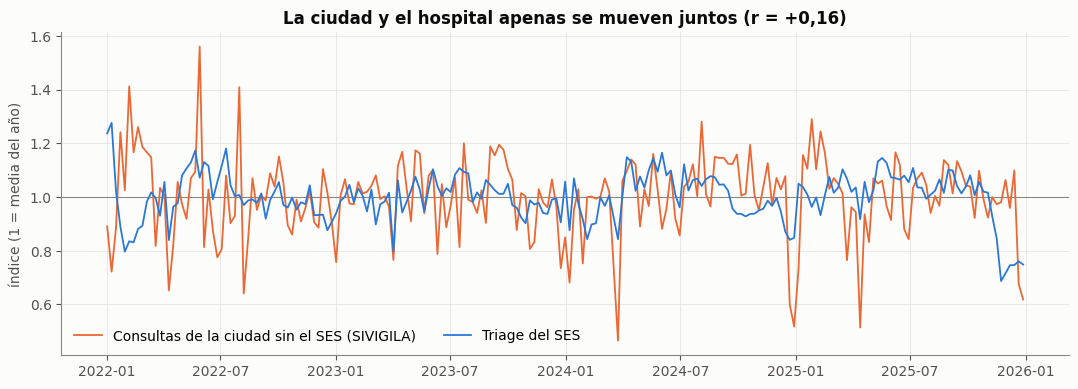

208 semanas 2022-2025
r en nivel (índice):          +0.165
r en cambio semana a semana:  +0.229
r del hospital con la ciudad L semanas antes: {-2: 0.097, -1: 0.078, 0: 0.165, 1: -0.0, 2: -0.056, 3: 0.02, 4: -0.0}
semanas con festivo (65): índice de la ciudad 0.88, del hospital 0.98; sin festivo (143): ciudad 1.06, hospital 1.01; mínimo de la ciudad 0.47


In [7]:
def indice(s):
    s = s.dropna()
    return s / s.groupby(s.index.year).transform("mean")
a = indice(ciudad.loc["2022-01-01":]); b_ = indice(tw.loc["2022-01-01":"2025-12-31"])
par = pd.concat([a.rename("ciudad"), b_.rename("hospital")], axis=1).dropna()
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.axhline(1, color=MUDO, lw=.8)
ax.plot(par.index, par.ciudad, color=NARANJA, lw=1.3, label="Consultas de la ciudad sin el SES (SIVIGILA)")
ax.plot(par.index, par.hospital, color=AZUL, lw=1.3, label="Triage del SES")
ax.set_ylabel("índice (1 = media del año)")
ax.set_title(f"La ciudad y el hospital apenas se mueven juntos (r = {par.ciudad.corr(par.hospital):+.2f})".replace(".", ","))
ax.legend(loc="lower left", ncol=2)
plt.show()
print(f"{len(par)} semanas 2022-2025")
print(f"r en nivel (índice):          {par.ciudad.corr(par.hospital):+.3f}")
print(f"r en cambio semana a semana:  {par.ciudad.diff().corr(par.hospital.diff()):+.3f}")
lag = {L: par.hospital.corr(par.ciudad.shift(L)) for L in range(-2, 5)}
print("r del hospital con la ciudad L semanas antes:", {k: round(v, 3) for k, v in lag.items()})

fw = W["es_festivo"].reindex(par.index).fillna(0) > 0
print(f"semanas con festivo ({int(fw.sum())}): índice de la ciudad {par.ciudad[fw].mean():.2f}, del hospital {par.hospital[fw].mean():.2f}; "
      f"sin festivo ({int((~fw).sum())}): ciudad {par.ciudad[~fw].mean():.2f}, hospital {par.hospital[~fw].mean():.2f}; mínimo de la ciudad {par.ciudad.min():.2f}")


## Lectura

**El hospital no sube y baja con la ciudad.**

- En nivel, r = +0,17; en cambio de una semana a otra, r = +0,23. Con rezago no hay relación: con la ciudad una semana antes, r es 0,00.
- **Las semanas festivas separan las dos series.** En las 65 semanas con algún festivo, el índice de la ciudad es 0,88 (mínimo de la ciudad 0,47) y el del hospital 0,98; en las 143 semanas sin festivo, 1,06 y 1,01.

**Por qué, al menos en parte.** El total de consultas del SIVIGILA suma consulta externa y urgencias, y la consulta externa es programada: en las semanas festivas las agendas se cierran y la serie de la ciudad cae, mientras el triage de urgencias casi no se mueve. Son dos demandas distintas. El total de la ciudad no mide la demanda urgente y, así como viene, no sirve de variable externa.

**Límite.** El SIVIGILA no trae una columna que separe urgencias de consulta externa. Una serie de urgencias de otras instituciones exigiría otra fuente, como los RIPS del SISPRO.

---
## Preparación de las series por subgrupo

Para las secciones 6 a 10 se arman el total y sus subgrupos (madrugada de 0 a 5 h, bandas de edad y aseguradora) como series diarias, y dos residuos contra el calendario. El **control A** lleva día de la semana, festivo y nivel del año, y deja libres las vacaciones y la temporada navideña, para no comerse el efecto que se quiere medir. El **control B** es el completo de las secciones 2 y 3. En ambos el ajuste excluye la ventana COVID, del 15 de marzo de 2020 al 28 de febrero de 2022, y las caídas de registro quedan como nulos en todos los subgrupos.

In [8]:
# ---------- series por subgrupo (hora, edad, asegurador) y residuos diarios por control
sys.path.insert(0, str(RAIZ))
from extraccion.entidades import clasificar          # solo clasifica nombres de aseguradoras

dias = pd.date_range("2020-01-01", FIN)
INI = "2022-03-01"                                   # inicio del periodo posterior a la ventana COVID
pct = lambda x: (np.exp(x) - 1) * 100

hor = pd.read_parquet(RAIZ / "salidas" / "triage_horario.parquet").assign(dia=lambda d: pd.to_datetime(d["dia"]))
madrugada = hor[hor.hora < 6].groupby("dia")["triages"].sum().reindex(dias).fillna(0)
edad = (pd.read_parquet(RAIZ / "salidas" / "triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d["dia"]))
          .pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0))
grp = (clasificar(pd.read_parquet(RAIZ / "salidas" / "triage_entidad.parquet"))
         .pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").reindex(dias).fillna(0))
seg = (pd.read_csv(RAIZ / "calendarios" / "seguridad_mindefensa.csv.gz", parse_dates=["fecha"])
         .set_index("fecha").reindex(dias))

S = pd.DataFrame({"total": tri_limpio.reindex(dias), "madrugada": madrugada, "0-4": edad["0-4"],
                  "15-44": edad["15-44"], "65+": edad["65-+"]}).join(grp)
S.loc[S.total.isna(), [c for c in S.columns if c != "total"]] = np.nan     # caida de registro: nulo en todo
S["lesiones_ciudad"] = seg["lesiones_personales"]

calc = (pd.read_csv(RAIZ / "calendarios" / "calendario_Colombia.csv", parse_dates=["fecha"])
          .set_index("fecha").reindex(dias))
fest = calc["es_festivo"].fillna(0).astype(int)
dow = pd.Series(dias.dayofweek, index=dias)
laboral = calc["es_habil"].fillna(0).eq(1)

anio = pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)
dsem = pd.get_dummies(dow, prefix="d", drop_first=True).astype(float)
# Control A: dia de la semana, festivo y nivel del anio. NO lleva vacaciones ni temporada navidena:
#            si las llevara, se comeria justo el efecto que se quiere medir.
# Control B: el control completo de las secciones 2 y 3.
ZA = pd.concat([dsem, fest.rename("festivo").astype(float), anio], axis=1); ZA.insert(0, "c", 1.0)
ZB = pd.concat([dsem, calc[CAL].apply(pd.to_numeric, errors="coerce").fillna(0), anio], axis=1); ZB.insert(0, "c", 1.0)
fuera = ~dias.to_series().between(*COVID).values

def residuo(y, Z):
    ly = np.log(y + 0.5); ok = fuera & y.notna().values
    b, *_ = np.linalg.lstsq(Z.values[ok], ly.values[ok], rcond=None)
    return (ly - Z.values @ b).where(y.notna())

COLS = ["total", "madrugada", "0-4", "15-44", "65+", "soat_aseguradora", "particular"]
RA = pd.DataFrame({c: residuo(S[c], ZA) for c in COLS + ["lesiones_ciudad"]}, index=dias)
RB = pd.DataFrame({c: residuo(S[c], ZB) for c in COLS}, index=dias)
print(f"residuo diario del total, control B: sd {RB.total.loc[INI:FIN].std():.3f}  |  control A: sd {RA.total.loc[INI:FIN].std():.3f}")

residuo diario del total, control B: sd 0.120  |  control A: sd 0.133


---
# 6. La Feria de Manizales

**Mecanismo.** Reloj de 0 a 5 días desde el inicio. Gatillo: una aglomeración que empieza, no un nivel. Condición: cae siempre en la primera quincena de enero, sobre el regreso de las vacaciones. Subgrupo esperado: accidentes de tránsito, visitantes sin aseguradora a mano y adultos de 15 a 44 años.

## 6.1 En el total

Residuo **diario** (sin día de la semana, festivos, temporada de fin de año ni nivel del año) alrededor del primer día de cada Feria. Cada línea gris es un año y la azul es la media. La franja amarilla es la duración típica de la Feria.

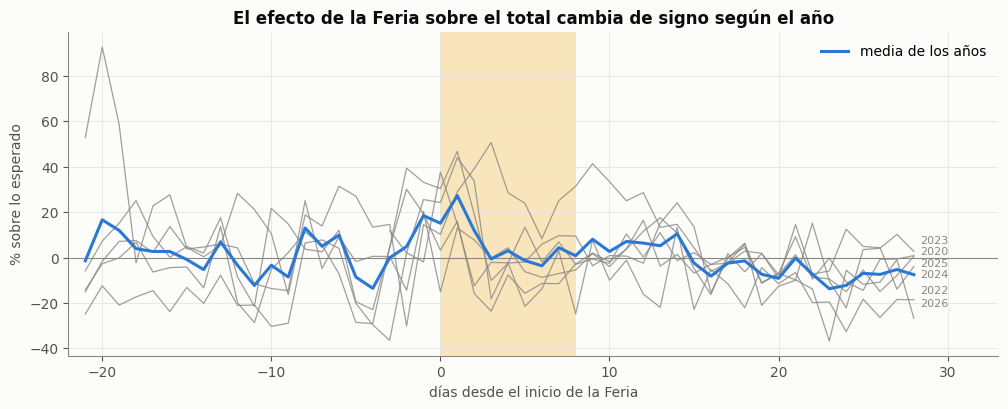

,antes (−21 a −1),Feria (0 a 8),después (9 a 28)
2020,13.1,11.6,-0.1
2022,19.5,27.3,1.2
2023,1.3,-2.0,0.2
2024,5.3,-7.7,-2.4
2025,-2.3,11.0,-1.2
2026,-15.4,-2.4,-13.3
media,3.6,6.3,-2.6
media sin 2022,0.4,2.1,-3.4
media sin 2020 ni 2022,-2.8,-0.3,-4.2


In [9]:
ventana = range(-21, 29)
curvas = {}
for _, f in ferias.iterrows():
    ini = pd.Timestamp(f.fecha_inicio)
    s = D.res.reindex([ini + pd.Timedelta(days=k) for k in ventana])
    s.index = list(ventana)
    curvas[ini.year] = (np.exp(s) - 1) * 100
M = pd.DataFrame(curvas)
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.axvspan(0, 8, color=AMARILLO, alpha=.25, lw=0)
ax.axhline(0, color=MUDO, lw=.8)
for c in M.columns:
    ax.plot(M.index, M[c], color=MUDO, lw=.9, alpha=.8)
    pass
ys = M.iloc[-8:].mean().sort_values()
pos, ult = {}, -1e9
for c, y in ys.items():
    ult = max(y, ult + 5); pos[c] = ult
for c, y in pos.items():
    ax.text(M.index[-1] + .4, y, str(c), fontsize=8, color=MUDO, va="center")
ax.set_xlim(-22, 33)
ax.plot(M.index, M.mean(axis=1), color=AZUL, lw=2.2, label="media de los años")
ax.set_xlabel("días desde el inicio de la Feria"); ax.set_ylabel("% sobre lo esperado")
ax.set_title("El efecto de la Feria sobre el total cambia de signo según el año")
ax.legend(loc="upper right")
plt.show()
res = pd.DataFrame({"antes (−21 a −1)": M.loc[-21:-1].mean(), "Feria (0 a 8)": M.loc[0:8].mean(),
                    "después (9 a 28)": M.loc[9:28].mean()}).round(1)
res.loc["media"] = res.mean().round(1)
res.loc["media sin 2022"] = res.loc[[2020, 2023, 2024, 2025, 2026]].mean().round(1)
res.loc["media sin 2020 ni 2022"] = res.loc[[2023, 2024, 2025, 2026]].mean().round(1)
res


## Lectura

**En el total, el efecto de la Feria no se sostiene de un año a otro.**

| | antes (−21 a −1) | Feria (0 a 8) | después (9 a 28) |
|---|---|---|---|
| media de los años | +3,6 % | +6,3 % | −2,6 % |
| media sin 2022 | +0,4 % | +2,1 % | −3,4 % |
| media sin 2020 ni 2022 | −2,8 % | −0,3 % | −4,2 % |
| 2022 | +19,5 | **+27,3** | +1,2 |
| 2024 | +5,3 | **−7,7** | −2,4 |
| 2025 | −2,3 | **+11,0** | −1,2 |
| 2026 | −15,4 | **−2,4** | −13,3 |

- La media sube un poco durante la Feria, pero **la diferencia entre años, de −7,7 a +27,3 %, es mucho mayor que la media**, y el día a día oscila ±12 %.
- **El +6,3 % depende del año 2022**, cuya Feria arranca el 2 de enero, dentro de la ventana COVID que el control no ajusta. Sin ese año la media baja a +2,1 %, y sin 2020 y 2022 a −0,3 %. La caída de 2026 en la ventana de «después» (−13,3 %) coincide con la caída del volumen de Nueva EPS.
- **El problema es de diseño, no de datos.** La Feria cae siempre en las dos primeras semanas de enero, sobre el regreso de las vacaciones y el fin de la temporada navideña. No hay ningún año sin Feria con el que compararla: la de 2021 se canceló, pero fue año de COVID. Con el total como desenlace, su efecto no se puede separar del calendario.

## 6.2 En su huella

Si la Feria tuviera un efecto propio, además del regreso de vacaciones, debería verse en los subgrupos que su mecanismo implica. Se comparan los días 0 a 4 desde su inicio con los mismos días tras **52 regresos de vacaciones o puentes de 3 días o más** (fuera de diciembre, enero y la ventana COVID). Son 5 Ferias: la de 2022 queda fuera por caer en la ventana COVID.

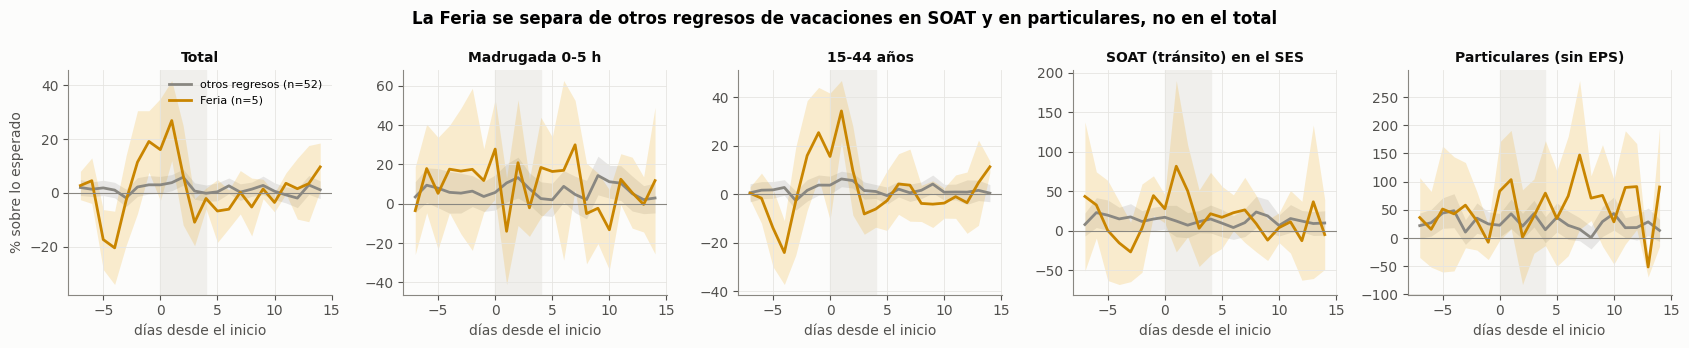

soat_aseguradora: 3.8 % del triage; exceso de la Feria sobre otros regresos +24.4 puntos -> aporta +0.92 puntos al total
particular: 0.8 % del triage; exceso de la Feria sobre otros regresos +32.4 puntos -> aporta +0.26 puntos al total


media días 0-4 (%)  ± IC95  \
Total                     otros regresos                 2.7     2.3   
                          Feria                          7.3     8.5   
Madrugada 0-5 h           otros regresos                 8.0     5.1   
                          Feria                         10.2     3.9   
15-44 años                otros regresos                 3.7     2.2   
                          Feria                          9.1     7.6   
SOAT (tránsito) en el SES otros regresos                12.5     8.5   
                          Feria                         36.9     5.5   
Particulares (sin EPS)    otros regresos                28.9    10.4   
                          Feria                         61.3    34.4   

                                          episodios  
Total                     otros regresos       52.0  
                          Feria                 5.0  
Madrugada 0-5 h           otros regresos       52.0  
                          Feria                 5.0  
15-44 años                otros regresos       52.0  
                          Feria                 5.0  
SOAT (tránsito) en el SES otros regresos       52.0  
                          Feria                 5.0  
Particulares (sin EPS)    otros regresos       52.0  
                          Feria                 5.0

In [10]:
# ---------- la Feria contra otros regresos de vacaciones, por subgrupo (dias 0 a 4)
ev = eventos[eventos.estado.isin(["realizado", "hibrido"]) & eventos.fecha_inicio.notna()]
f_ini = [pd.Timestamp(x) for x in ev[ev.nombre_evento.eq("Feria de Manizales")].fecha_inicio]
f_ini = [f for f in f_ini if not (pd.Timestamp(COVID[0]) <= f <= pd.Timestamp(COVID[1]))]
bloque = calc.es_no_laboral.fillna(0).eq(1)
largo = bloque.groupby((~bloque).cumsum()).transform("sum").where(bloque, 0)
regreso = (~bloque) & bloque.shift(1, fill_value=False) & largo.shift(1).fillna(0).ge(3)
otros = [d for d in regreso[regreso].index if d.month not in (12, 1)
         and not (pd.Timestamp(COVID[0]) <= d <= pd.Timestamp(COVID[1])) and d <= pd.Timestamp(FIN) - pd.Timedelta(days=14)]

def curva(serie, fechas, k=range(-7, 15)):
    return pd.DataFrame({f: serie.reindex([f + pd.Timedelta(days=i) for i in k]).values for f in fechas}, index=list(k))

cols = {"total": "Total", "madrugada": "Madrugada 0-5 h", "15-44": "15-44 años",
        "soat_aseguradora": "SOAT (tránsito) en el SES", "particular": "Particulares (sin EPS)"}
resumen = {}
fig, axes = plt.subplots(1, len(cols), figsize=(17, 3.5), sharex=True)
for ax, (c, nom_c) in zip(axes, cols.items()):
    for fechas, col, nom in [(otros, MUDO, f"otros regresos (n={len(otros)})"), (f_ini, AMARILLO, f"Feria (n={len(f_ini)})")]:
        cu = pct(curva(RB[c], fechas)); m = cu.mean(axis=1); e = 1.96 * cu.std(axis=1) / np.sqrt(cu.notna().sum(axis=1))
        ax.fill_between(m.index, m - e, m + e, color=col, alpha=.18, lw=0)
        ax.plot(m.index, m, color=col if col != AMARILLO else "#c98500", lw=2, label=nom)
        v = cu.loc[0:4].mean()
        resumen[(nom_c, nom.split(" (")[0])] = (v.mean(), 1.96 * v.std() / np.sqrt(v.notna().sum()), int(v.notna().sum()))
    ax.axvspan(0, 4, color="#f0efec", zorder=0); ax.axhline(0, color=MUDO, lw=.8)
    ax.set_title(nom_c, fontsize=10); ax.set_xlabel("días desde el inicio")
axes[0].set_ylabel("% sobre lo esperado"); axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("La Feria se separa de otros regresos de vacaciones en SOAT y en particulares, no en el total", fontweight="bold")
plt.tight_layout(); plt.show()
T_feria = pd.DataFrame(resumen, index=["media días 0-4 (%)", "± IC95", "episodios"]).T.round(1)
cuota = {c: (S[c] / S.total).loc[INI:FIN].mean() for c in ["soat_aseguradora", "particular"]}
exceso = {c: T_feria.loc[(n, "Feria"), "media días 0-4 (%)"] - T_feria.loc[(n, "otros regresos"), "media días 0-4 (%)"]
          for c, n in [("soat_aseguradora", "SOAT (tránsito) en el SES"), ("particular", "Particulares (sin EPS)")]}
for c in cuota:
    print(f"{c}: {100 * cuota[c]:.1f} % del triage; exceso de la Feria sobre otros regresos {exceso[c]:+.1f} puntos "
          f"-> aporta {exceso[c] * cuota[c]:+.2f} puntos al total")
T_feria

## Lectura

**La Feria no es un regreso de vacaciones cualquiera: tiene huella propia en el SOAT y en los particulares, aunque no en el total.** Media de los días 0 a 4, en % sobre lo esperado:

| | Otros regresos (n = 52) | **Feria (n = 5)** |
|---|---|---|
| Total | +2,7 ± 2,3 | +7,3 ± 8,5 |
| Madrugada 0-5 h | +8,0 ± 5,1 | +10,2 ± 3,9 |
| 15-44 años | +3,7 ± 2,2 | +9,1 ± 7,6 |
| **SOAT (tránsito)** | +12,5 ± 8,5 | **+36,9 ± 5,5** |
| **Particulares (sin EPS)** | +28,9 ± 10,4 | **+61,3 ± 34,4** |

- **Los accidentes de tránsito atendidos con SOAT se triplican respecto de un regreso normal.** Es la diferencia más limpia. Con solo 5 Ferias el intervalo normal es optimista: con la distribución t de 4 grados de libertad el margen del SOAT sube de ±5,5 a unos ±7,8, y la Feria sigue separada de los otros regresos.
- **Los que llegan sin asegurador se duplican**, con un intervalo ancho por tener pocas Ferias, y siguen altos varios días después del día 4. Encaja con visitantes de fuera o con quien no tiene su EPS a mano.
- **El total apenas se mueve** porque esos subgrupos son pequeños: el SOAT aporta unos 0,9 puntos al total y los particulares unos 0,3 (sección 4). Es la dilución que hace invisible la Feria en el total y visible en su huella.
- **Parte de la subida empieza antes del día 0**: los días del 1 y el 2 de enero son Año Nuevo, y con 5 Ferias no se puede separar del todo.

**Lectura por mecanismo.** El reloj es corto (0 a 5 días), el gatillo es el inicio de la aglomeración, la condición es que cae sobre un regreso de vacaciones, y el subgrupo es SOAT y particulares. Un indicador de «hay Feria» sobre el total promedia un efecto de 37 % en el 4 % del triage y lo borra.

**Límites.** Cinco Ferias son pocas; el intervalo de los particulares es ancho; y la serie de lesiones de tránsito de la ciudad no acompaña al SOAT del SES de forma general, solo en la Feria (cuaderno 07).

---
# 7. La mitad del año

**Mecanismo.** Reloj de semanas. Gatillo: una temporada, no un día. Condición: la mitad del año coincide con las vacaciones escolares, la temporada respiratoria y las fiestas de los pueblos de finales de junio. Subgrupo esperado: los menores.

Se miran las **semanas de vacaciones escolares oficiales** de cada año (resoluciones de la Secretaría de Educación de Manizales) y, como ventana añadida después de ver los datos, marzo a mayo. La figura muestra, año por año, el residuo semanal del total de febrero a agosto, con las vacaciones sombreadas y las consultas por IRA de la ciudad (SIVIGILA, sin el SES) en índice.

Se usan **dos controles**, a propósito. El control A lleva día de la semana, festivo y nivel del año, y no lleva ninguna variable de vacaciones. El control B es el completo de las secciones 2 a 3 e incluye el indicador de vacaciones del calendario general. El contraste entre ambos muestra qué ocurre cuando el control contiene la variable que se quiere estudiar.

indicador de vacaciones del calendario general, mitad de 2022: 01-06 a 31-07; receso oficial: 20-06 a 10-07


indicador de vacaciones del calendario general, mitad de 2026: 01-06 a 31-07; receso oficial: 15-06 a 05-07
días marcados como vacaciones por año en el calendario general: {2020: 122, 2021: 122, 2022: 122, 2023: 122, 2024: 122, 2025: 122, 2026: 100}


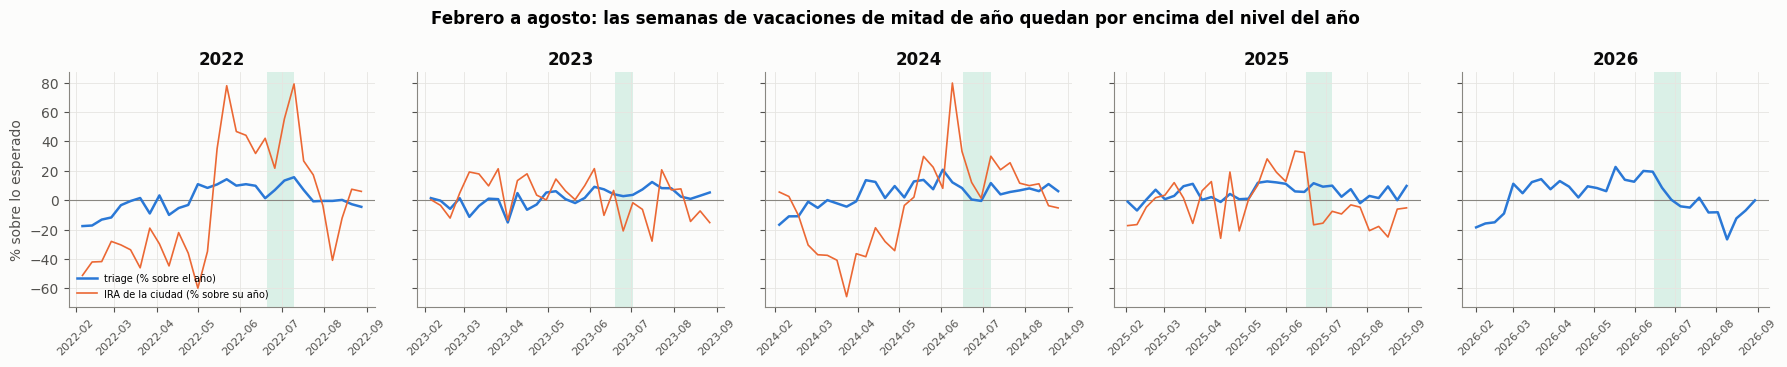

,"vacaciones, control A","vacaciones, control B","marzo-mayo, control A"
año,,,
2022,9.1,5.0,1.8
2023,3.5,-1.8,-1.9
2024,4.8,-0.0,5.0
2025,9.0,3.9,5.1
2026,5.6,1.6,10.4
media,6.4,1.7,4.1


In [11]:
# ---------- la mitad del año, con las fechas oficiales de vacaciones de cada año
esc = pd.read_csv(RAIZ / "calendarios" / "calendario_escolar_manizales.csv", parse_dates=["fecha_inicio", "fecha_fin"])
vac = esc[(esc.tipo == "mitad_de_anio") & esc.anio_lectivo.between(2022, 2026)].set_index("anio_lectivo")

def semanal(s):
    w = s.resample("W-SAT").mean().rename(lambda i: i - pd.Timedelta(days=6))
    return w[s.resample("W-SAT").count().values == 7]
wA, wB = semanal(RA.total), semanal(RB.total)
for a in (2022, 2026):
    m_ = calc.es_vacaciones_escolares.loc[f"{a}-05-15":f"{a}-08-15"].fillna(0).eq(1)
    print(f"indicador de vacaciones del calendario general, mitad de {a}: {m_[m_].index.min():%d-%m} a {m_[m_].index.max():%d-%m}; "
          f"receso oficial: {vac.loc[a, 'fecha_inicio']:%d-%m} a {vac.loc[a, 'fecha_fin']:%d-%m}")
print("días marcados como vacaciones por año en el calendario general:",
      calc.es_vacaciones_escolares.fillna(0).groupby(dias.year).sum().astype(int).to_dict())
inst_ira = inst[inst.cod_upgd.ne(SES)].groupby("fecha_inicio_semana")["consultas_ira"].sum()

fig, axes = plt.subplots(1, 5, figsize=(18, 3.7), sharey=True)
filas = []
for ax, (a, r) in zip(axes, vac.iterrows()):
    s = pct(wA.loc[f"{a}-02-01":f"{a}-08-31"])
    ax.axhline(0, color=MUDO, lw=.8)
    ax.axvspan(r.fecha_inicio, r.fecha_fin, color=AQUA, alpha=.15, lw=0)
    ax.plot(s.index, s.values, color=AZUL, lw=1.8, label="triage (% sobre el año)")
    ii = inst_ira.loc[f"{a}-02-01":f"{a}-08-31"]
    if len(ii) > 5:
        ax.plot(ii.index, 100 * (ii / inst_ira.loc[f"{a}"].mean() - 1), color=NARANJA, lw=1.2, label="IRA de la ciudad (% sobre su año)")
    ax.set_title(str(a)); ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    en_vac = lambda w: w[(w.index >= r.fecha_inicio - pd.Timedelta(days=6)) & (w.index <= r.fecha_fin)]
    filas.append({"año": a, "vacaciones, control A": pct(en_vac(wA).mean()), "vacaciones, control B": pct(en_vac(wB).mean()),
                  "marzo-mayo, control A": pct(wA[wA.index.month.isin([3, 4, 5]) & (wA.index.year == a)].mean())})
axes[0].set_ylabel("% sobre lo esperado"); axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Febrero a agosto: las semanas de vacaciones de mitad de año quedan por encima del nivel del año", fontweight="bold")
plt.tight_layout(); plt.show()
T_mitad = pd.DataFrame(filas).set_index("año"); T_mitad.loc["media"] = T_mitad.mean()
T_mitad.round(1)

## Lectura

**La mitad del año es la parte alta del año, y un control que ya contiene las vacaciones la hace desaparecer.**

| Año | Vacaciones, control A | Vacaciones, control B | Marzo-mayo, control A |
|---|---|---|---|
| 2022 | **+9,1 %** | +5,0 % | +1,8 % |
| 2023 | +3,5 % | −1,8 % | −1,9 % |
| 2024 | +4,8 % | 0,0 % | +5,0 % |
| 2025 | **+9,0 %** | +3,9 % | +5,1 % |
| 2026 | +5,6 % | +1,6 % | **+10,4 %** |
| **Media** | **+6,4 %** | **+1,7 %** | **+4,1 %** |

- **Las semanas de vacaciones de mitad de año quedan por encima del nivel del año los cinco años** con el control A, de +3,5 a +9,1 %. Con el control B la media baja a +1,7 % y en dos años queda en cero o por debajo. La diferencia no es de los datos: el indicador de vacaciones del calendario general descuenta justamente lo que se quería medir. Un control que incluye la variable de estudio la hace desaparecer.
- **El indicador de vacaciones del calendario general no coincide con el receso oficial.** Marca 122 días cada año de 2020 a 2025, y en la mitad del año cubre del 1 de junio al 31 de julio, mientras el receso oficial de 2022 va del 20 de junio al 10 de julio y el de 2026 del 15 de junio al 5 de julio. Para medir el efecto se usan las fechas oficiales de cada año.
- **Las semanas altas sostenidas se concentran de mayo a julio** (sección 9): con el control A, 45 % de las semanas de mayo, 48 % de las de junio y 23 % de las de julio; con el control B, junio y julio bajan a 14 %. El nivel medio de mayo y junio supera en 8,9 y 9,2 % al del año.
- **La IRA de la ciudad sube con fuerza entre mayo y julio en 2022 y en junio de 2024**, que es la temporada respiratoria de mitad de año; en 2023 y 2025 es más plana. El triage no sigue a la IRA semana a semana (secciones 3 y 10), pero ambas comparten temporada.

**Lectura por mecanismo.** El reloj es de semanas, el gatillo es una temporada y la condición es el receso escolar. La subida del total es moderada (+6 %) y, por el tamaño del servicio, no se atribuye a un subgrupo concreto en este cuaderno.

**Límites.**
- Con cinco años no se puede separar «vacaciones» de «temporada respiratoria» de «fiestas de los pueblos de finales de junio»: caen juntas.
- **Julio de 2026 queda afectado por la caída del volumen de Nueva EPS**, y marzo-mayo de 2026 (+10,4 %) por su recuperación parcial; ninguno de los dos es efecto de las vacaciones (cuaderno 07).

---
# 8. Diciembre y el arranque de enero

**Mecanismo.** Reloj de horas a 3 días. Gatillo: la noche festiva (velitas, 24, 25 y 31 de diciembre, 1 de enero) y el día que le sigue. Condición: días no laborales, con alcohol, aglomeración y pólvora. Subgrupo esperado: madrugada, particulares y adultos jóvenes.

## 8.1 Las noches festivas

Efecto de cada noche frente a **los demás domingos y festivos del año**, que tampoco son días laborales, con el control A (sin temporada navideña, que se comería el efecto). El contraste externo son las **lesiones personales registradas por la Policía** ese mismo día en toda la ciudad.

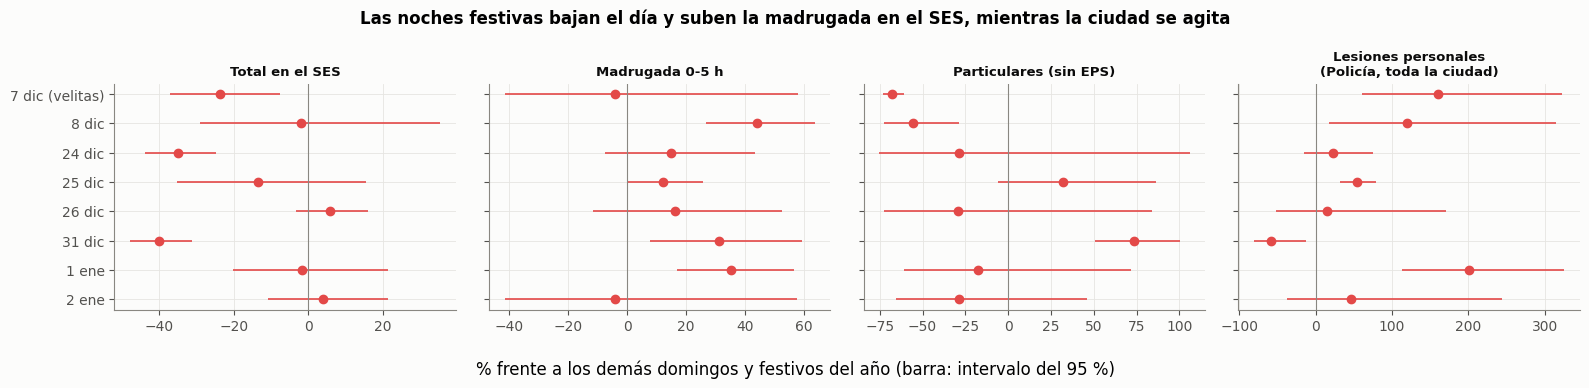

Lesiones por pólvora en Manizales (vigilancia, 2015-2025): 163 casos; 131 (80 %) en semanas de diciembre y enero; 1.34 casos por semana en temporada frente a 0.07 el resto del año


serie,Total en el SES,Madrugada 0-5 h,Particulares (sin EPS),"Lesiones personales\n(Policía, toda la ciudad)"
noche,,,,
7 dic (velitas),-24.0,-4.0,-68.0,161.0
8 dic,-2.0,44.0,-56.0,120.0
24 dic,-35.0,15.0,-29.0,22.0
25 dic,-13.0,12.0,32.0,54.0
26 dic,6.0,16.0,-29.0,14.0
31 dic,-40.0,31.0,74.0,-59.0
1 ene,-2.0,35.0,-18.0,201.0
2 ene,4.0,-4.0,-29.0,46.0


In [12]:
# ---------- diciembre: las noches festivas contra los demas domingos y festivos del año
fechas_dic = []
for a in range(2020, 2027):
    for m, d in [(12, 7), (12, 8), (12, 24), (12, 25), (12, 26), (12, 31), (1, 1), (1, 2)]:
        f = pd.Timestamp(a, m, d)
        if f in RA.index and not (pd.Timestamp(COVID[0]) <= f <= pd.Timestamp(COVID[1])): fechas_dic.append(f)
fechas_dic = pd.DatetimeIndex(sorted(set(fechas_dic)))
comparador = RA.index[((dow == 6) | (fest == 1)).values & ~RA.index.isin(fechas_dic) & ~RA.index.month.isin([12, 1]) & fuera]
nombres = {(12, 7): "7 dic (velitas)", (12, 8): "8 dic", (12, 24): "24 dic", (12, 25): "25 dic", (12, 26): "26 dic",
           (12, 31): "31 dic", (1, 1): "1 ene", (1, 2): "2 ene"}
cols = {"total": "Total en el SES", "madrugada": "Madrugada 0-5 h", "particular": "Particulares (sin EPS)",
        "lesiones_ciudad": "Lesiones personales\n(Policía, toda la ciudad)"}
filas = []
for c, nom in cols.items():
    base = RA[c].loc[comparador].dropna()
    for (m, d), nd in nombres.items():
        x = RA[c].loc[[f for f in fechas_dic if f.month == m and f.day == d]].dropna()
        if len(x) < 2: continue
        dif = x.mean() - base.mean(); e = 1.96 * np.sqrt(x.var() / len(x) + base.var() / len(base))
        filas.append({"serie": nom, "noche": nd, "efecto %": pct(dif), "bajo": pct(dif - e), "alto": pct(dif + e), "años": len(x)})
T_dic = pd.DataFrame(filas)
orden = list(nombres.values())
fig, axes = plt.subplots(1, len(cols), figsize=(16, 3.8), sharey=True)
for ax, (s, g) in zip(axes, T_dic.groupby("serie", sort=False)):
    g = g.set_index("noche").reindex(orden).dropna()
    y = [orden.index(i) for i in g.index]
    ax.errorbar(g["efecto %"], y, xerr=[g["efecto %"] - g.bajo, g.alto - g["efecto %"]], fmt="o", color=ROJO, ms=6, lw=1.2)
    ax.axvline(0, color=MUDO, lw=.8); ax.set_title(s, fontsize=9.5)
axes[0].set_yticks(range(len(orden)), orden); axes[0].invert_yaxis()
fig.suptitle("Las noches festivas bajan el día y suben la madrugada en el SES, mientras la ciudad se agita", fontweight="bold")
fig.supxlabel("% frente a los demás domingos y festivos del año (barra: intervalo del 95 %)"); plt.tight_layout(); plt.show()
man452 = vig[vig.ambito.eq("manizales") & vig.evento.eq(452)]
v452 = man452[man452.variable.eq("casos_ocurrencia")].groupby("fecha_inicio_semana")["valor"].sum().loc["2015":]
temp = v452.index.month.isin([12, 1])
print(f"Lesiones por pólvora en Manizales (vigilancia, 2015-2025): {int(v452.sum())} casos; {int(v452[temp].sum())} "
      f"({100 * v452[temp].sum() / v452.sum():.0f} %) en semanas de diciembre y enero; "
      f"{v452[temp].mean():.2f} casos por semana en temporada frente a {v452[~temp].mean():.2f} el resto del año")
T_dic.pivot_table(index="noche", columns="serie", values="efecto %", sort=False).reindex(orden).round(0)

## Lectura

**Las noches festivas no suben el día en el SES: lo mueven a la madrugada y a otra población, mientras la ciudad se agita.**

| Noche | Total | Madrugada | Particulares | Lesiones (Policía, ciudad) |
|---|---|---|---|---|
| 7 dic (velitas) | **−24 %** | −4 % | **−68 %** | **+161 %** |
| 8 dic | −2 % | **+44 %** | **−56 %** | **+120 %** |
| 24 dic | **−35 %** | +15 % | −29 % | +22 % |
| 25 dic | −13 % | +12 % | +32 % | **+54 %** |
| 31 dic | **−40 %** | **+31 %** | **+74 %** | **−59 %** |
| 1 ene | −2 % | **+35 %** | −18 % | **+201 %** |

En negrita, las marcas cuya barra no cruza el cero en la figura.

1. **En la ciudad las noches de fiesta son violentas.** Las lesiones personales de la Policía se multiplican por 2,6 en velitas, por 2,2 el 8 de diciembre y por 3 el 1 de enero. El 31 aparece bajo (−59 %), probablemente porque las riñas de esa noche caen después de medianoche, ya el 1 de enero.
2. **En el SES el día completo baja** en velitas, el 24 y el 31, de un 24 a un 40 % frente a otro festivo: la gente está en casa o de fiesta. **La madrugada sube**: +44 % la madrugada del 8 de diciembre, +31 % la del 31 y +35 % la del 1 de enero. Lo que llega es de noche.
3. **El 31 llegan +74 % de particulares**, personas sin asegurador a mano, lo que encaja con visitantes y con quien no pasa por su EPS en festivo.
4. **La pólvora es real, pero pequeña en el conteo.** El cuaderno imprime el cálculo: de los quemados de Manizales del SIVIGILA, el 80 % cae en diciembre y enero (131 de 163 casos, 2015-2025), con 1,3 casos por semana en temporada frente a 0,07 el resto del año. Frente a unos 177 triages diarios, no explica el pico por sí sola.

**Lectura por mecanismo.** El reloj es de horas a 3 días y la fecha se conoce con meses de antelación. El gatillo es la noche de fiesta y la condición es que sea un día no laboral. El subgrupo es la madrugada y los particulares: un indicador único de «festivo» promedia el día que baja y la madrugada que sube, y los borra.

**Límites.** Cada noche tiene 4 o 5 años de datos, de modo que los intervalos son anchos. La serie de la Policía es de toda la ciudad y no dice cuántos de esos lesionados llegaron al SES.

## 8.2 La temporada día por día

Residuo del total (control A) del 1 de diciembre al 31 de enero, un año por línea, con la media en azul. Se usan las cuatro temporadas que empiezan en diciembre de 2022 a 2025: la de 2021-2022 cae en la ventana COVID y queda fuera. Las marcas son el 7 de diciembre, el 24, el 25, el 31 y el 1 de enero.

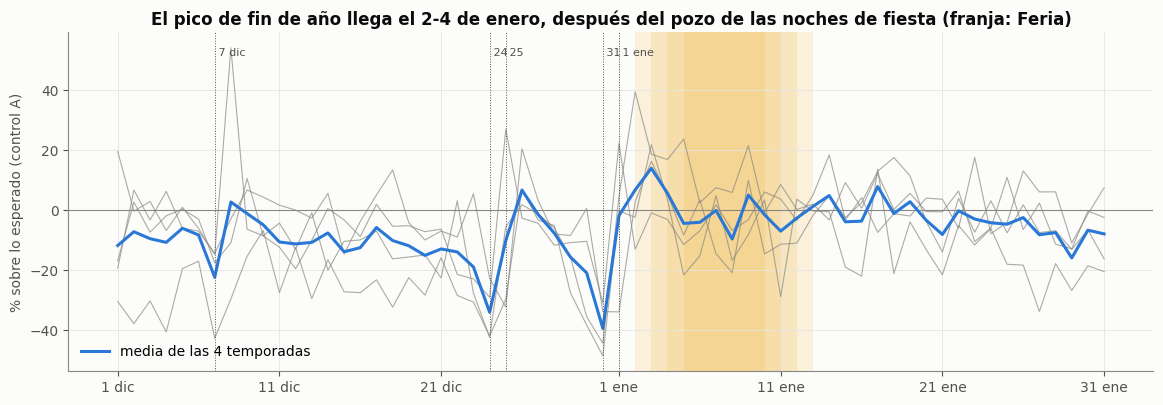

,media %,temporadas
03-Jan,14.0,4
17-Jan,7.8,4
02-Jan,6.7,4
26-Dec,6.7,4
04-Jan,5.6,4
09-Jan,5.0,4
14-Jan,4.9,4
19-Jan,2.8,4


In [13]:
# ---------- la temporada dia por dia: 1 de diciembre a 31 de enero, un año por linea
curvas = {}
for a in range(2023, 2027):          # desde dic-2022: la temporada 2021-22 cae en la ventana COVID, fuera del ajuste
    ini = pd.Timestamp(a - 1, 12, 1); fin_ = pd.Timestamp(a, 1, 31)
    s = RA.total.loc[ini:fin_]
    s.index = (s.index - ini).days
    curvas[f"{a-1}-{a}"] = pct(s)
Mx = pd.DataFrame(curvas)
fig, ax = plt.subplots(figsize=(14, 4.4))
ax.axhline(0, color=MUDO, lw=.8)
for c in Mx.columns: ax.plot(Mx.index, Mx[c], color=MUDO, lw=.8, alpha=.7)
ax.plot(Mx.index, Mx.mean(axis=1), color=AZUL, lw=2.2, label="media de las 4 temporadas")
for k, t in {6: "7 dic", 23: "24", 24: "25", 30: "31", 31: "1 ene"}.items():
    ax.axvline(k, color=TINTA2, lw=.7, ls=":"); ax.text(k, Mx.max().max() * .95, " " + t, fontsize=8, color=TINTA2)
for f in f_ini:
    k = (f - pd.Timestamp(f.year - 1, 12, 1)).days
    if 0 <= k <= 61 and f.year >= 2023: ax.axvspan(k, k + 8, color=AMARILLO, alpha=.12, lw=0)
ax.set_xticks([0, 10, 20, 31, 41, 51, 61], ["1 dic", "11 dic", "21 dic", "1 ene", "11 ene", "21 ene", "31 ene"])
ax.set_ylabel("% sobre lo esperado (control A)"); ax.legend(loc="lower left")
ax.set_title("El pico de fin de año llega el 2-4 de enero, después del pozo de las noches de fiesta (franja: Feria)")
plt.show()
top = pd.DataFrame({"media %": Mx.mean(axis=1).round(1), "temporadas": Mx.notna().sum(axis=1)})
top.index = [(pd.Timestamp(2021, 12, 1) + pd.Timedelta(days=int(i))).strftime("%d-%b") for i in top.index]
top.sort_values("media %", ascending=False).head(8)

## Lectura

**El pico de fin de año llega los días después de la fiesta, no en la noche de fiesta.** Los días más altos, en media de las cuatro temporadas:

| Día | Media sobre lo esperado |
|---|---|
| **3 de enero** | **+14,0 %** |
| 17 de enero | +7,8 % |
| 2 de enero | +6,7 % |
| 26 de diciembre | +6,7 % |
| 4 de enero | +5,6 % |
| 9 de enero | +5,0 % |

- La figura muestra un **pozo seguido de rebote**: las noches del 24 y del 31 hunden el conteo (−35 y −40 %), y los días posteriores quedan por encima de lo normal, sobre todo del 2 al 4 de enero. La consecuencia de la fiesta llega después, cuando la gente decide consultar o vuelve el servicio normal.
- **Del 2 al 4 de enero se juntan tres cosas que no se pueden separar con cuatro temporadas**: el día después de Año Nuevo, el regreso de las vacaciones y el arranque de la Feria (franja amarilla), a veces con el Carnaval de Riosucio, que según el calendario de fiestas de Caldas cae en enero de los años impares. La sección 6 mostró que la Feria tiene huella propia en el SOAT, pero ese efecto es de un subgrupo pequeño.
- El segundo máximo, el 17 de enero, no tiene una explicación en los calendarios disponibles.

---
# 9. Los picos: días puntuales y semanas altas

Un día es **pico puntual** si queda más de 1,5 desviaciones por encima del nivel local, que es la mediana de los 14 días antes y después, con el control B. Una **semana alta sostenida** es una semana cuya media supera en una desviación el nivel del año, **sin** quitar la estacionalidad (control A). La primera es una noche; la segunda, una temporada. La tercera figura da el nivel medio del mes con el control A.

El nivel local, y no la media del año, es la referencia porque el año se parte con los escalones de la red de salud: contra la media anual, un desplome de nivel fabrica días bajos y esconde días altos. Además es la pregunta del proyecto, que siempre es respecto de lo que se venía viendo.

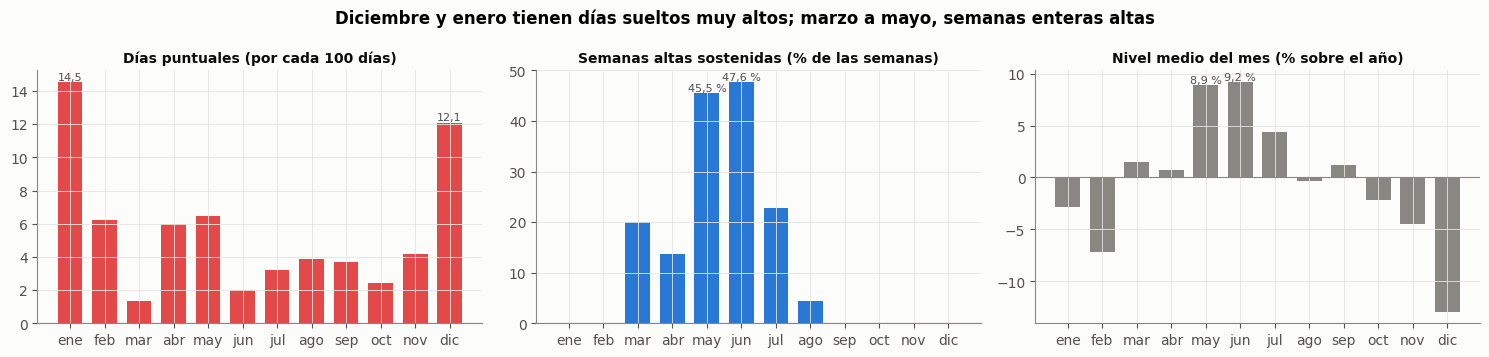

,días puntuales /100 días,semanas altas %,"semanas altas %, con vacaciones en el control",nivel del mes %
ene,14.5,0.0,6.0,-2.8
feb,6.2,0.0,0.0,-7.2
mar,1.4,20.0,25.0,1.5
abr,6.0,14.0,23.0,0.7
may,6.5,45.0,45.0,8.9
jun,2.0,48.0,14.0,9.2
jul,3.2,23.0,14.0,4.4
ago,3.9,4.0,9.0,-0.4
sep,3.7,0.0,15.0,1.2
oct,2.4,0.0,0.0,-2.2


In [14]:
# ---------- dos tipos de pico, por mes (control B; el nivel local es la mediana de +-14 dias)
meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
V = RB.total.loc[INI:FIN]
local = V - V.rolling(29, center=True, min_periods=20).median()
sd_loc = local.std()
p15 = local > 1.5 * sd_loc
dias_mes = local.notna().groupby(local.index.month).sum()
puntuales = 100 * p15.groupby(p15.index.month).sum() / dias_mes
VA = RA.total.loc[INI:FIN]                          # semanas altas: control A, sin quitar la estacionalidad
w = VA.resample("W-SAT").mean()[VA.resample("W-SAT").count() == 7]
alta = w > w.std()
sostenidas = 100 * alta.groupby(alta.index.month).mean()
nivel = pct(VA.groupby(VA.index.month).mean())
wb_ = V.resample("W-SAT").mean()[V.resample("W-SAT").count() == 7]
sostenidas_B = 100 * (wb_ > wb_.std()).groupby(wb_.index.month).mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, s, t, col, u in [(axes[0], puntuales, "Días puntuales (por cada 100 días)", ROJO, ""),
                         (axes[1], sostenidas, "Semanas altas sostenidas (% de las semanas)", AZUL, " %"),
                         (axes[2], nivel, "Nivel medio del mes (% sobre el año)", MUDO, " %")]:
    s = s.reindex(range(1, 13)).fillna(0)
    ax.bar(range(12), s.values, color=col, width=.72)
    ax.set_xticks(range(12), meses); ax.set_title(t, fontsize=10); ax.axhline(0, color=MUDO, lw=.8)
    for i in s.values.argsort()[-2:]:
        ax.text(i, s.values[i], f"{s.values[i]:.1f}{u}".replace(".", ","), ha="center", va="bottom", fontsize=8, color=TINTA2)
fig.suptitle("Diciembre y enero tienen días sueltos muy altos; marzo a mayo, semanas enteras altas", fontweight="bold")
plt.tight_layout(); plt.show()
T_picos = pd.DataFrame({"días puntuales /100 días": puntuales.round(1), "semanas altas %": sostenidas.round(0),
                        "semanas altas %, con vacaciones en el control": sostenidas_B.round(0),
                        "nivel del mes %": nivel.round(1)}).reindex(range(1, 13)); T_picos.index = meses
T_picos

## Lectura

**Hay dos tipos de pico, y se anticipan con variables distintas.**

| | Días puntuales (por 100 días) | Semanas altas, control A (%) | Semanas altas, con vacaciones en el control (%) | Nivel del mes |
|---|---|---|---|---|
| **Enero** | **14,5** | 0 | 6 | −2,8 % |
| **Diciembre** | **12,1** | 0 | 17 | −12,9 % |
| Marzo | 1,4 | 20 | 25 | +1,5 % |
| Abril | 6,0 | 14 | 23 | +0,7 % |
| **Mayo** | 6,5 | **45** | 45 | **+8,9 %** |
| **Junio** | 2,0 | **48** | 14 | **+9,2 %** |
| Julio | 3,2 | 23 | 14 | +4,4 % |
| Octubre-noviembre | 2,4 y 4,2 | 0 | 0 | −2,2 y −4,5 % |

- **Diciembre y enero tienen días sueltos muy altos dentro de meses que en conjunto son bajos.** Son noches y días concretos, no temporadas. Su nivel medio es negativo porque los días de fiesta y de familia bajan el conteo.
- **De mayo a julio hay semanas enteras altas**: es una temporada, y es la parte alta del año (sección 7). Con las vacaciones dentro del control, junio y julio parecen bajos; sin ellas, junio es el mes con más semanas altas.
- **Octubre y noviembre no tienen ni una semana alta.**
- Un pico de diciembre y uno de mayo piden variables distintas para anticiparlos: el de diciembre, el calendario festivo, que se conoce con meses de antelación; el de mayo, lo que viene subiendo desde semanas antes y el calendario escolar.

**Los 30 días pico y lo que los precede.** Pico es más de 2 desviaciones sobre el nivel local (+22 %). Son 30 días; 10 caen en domingo y 8 en sábado, 9 en enero y 6 en diciembre. Frente a un día normal, los antecedentes son:

| Antecedente | % de los picos | % de los días normales | Razón |
|---|---|---|---|
| Feria, 0 a 5 días antes | 16,7 % (5 picos) | 3,1 % | 5,3 |
| Otro evento social, 0 a 5 días antes | 60,0 % (18 picos) | 29,9 % | 2,0 |
| Regreso de un bloque no laboral de 3 días o más, 0 a 2 días antes | 16,7 % (5 picos) | 10,8 % | 1,5 |

In [15]:
# ---------- los 30 dias pico (mas de 2 desviaciones sobre el nivel local) y lo que los precede
pico = local > 2 * sd_loc
print(f"{int(pico.sum())} días pico (umbral +{pct(2 * sd_loc):.0f} %); por día de la semana:",
      pico[pico].index.day_name().value_counts().to_dict())
print("por mes:", pico[pico].index.month.value_counts().sort_index().to_dict())

def banda_dias(ini_, fin_):
    s = pd.Series(False, index=dias)
    for a, b in zip(ini_, fin_): s.loc[pd.Timestamp(a):pd.Timestamp(b)] = True
    return s
dia_evento = banda_dias(ev.fecha_inicio, ev.fecha_fin.fillna(ev.fecha_inicio))
f_todas = ev[ev.nombre_evento.eq("Feria de Manizales")]
dia_feria = banda_dias(f_todas.fecha_inicio, f_todas.fecha_fin)
def antes(senal, desde, hasta):
    return senal.astype(float).shift(desde).rolling(hasta - desde + 1, min_periods=1).max().fillna(0).astype(bool)
ANT = {"Feria, 0-5 días antes": antes(dia_feria, 0, 5),
       "otro evento social, 0-5 días antes": antes(dia_evento, 0, 5),
       "regreso de un bloque no laboral (3 días o más), 0-2 días antes": antes(regreso, 0, 2)}
base_ok = local.notna()
filas = []
for k, s in ANT.items():
    s = s.reindex(V.index); a, b = s[pico].mean(), s[base_ok & ~pico].mean()
    filas.append({"antecedente": k, "% de los picos": round(100 * a, 1), "% de los días normales": round(100 * b, 1),
                  "razón": round(a / b, 2), "picos con él": int(s[pico].sum())})
pd.DataFrame(filas).set_index("antecedente")

30 días pico (umbral +22 %); por día de la semana: {'Sunday': 10, 'Saturday': 8, 'Thursday': 6, 'Wednesday': 3, 'Friday': 2, 'Monday': 1}
por mes: {1: 9, 2: 3, 4: 3, 5: 4, 7: 2, 8: 2, 11: 1, 12: 6}


,% de los picos,% de los días normales,razón,picos con él
antecedente,,,,
"Feria, 0-5 días antes",16.7,3.1,5.30,5
"otro evento social, 0-5 días antes",60.0,29.9,2.01,18
"regreso de un bloque no laboral (3 días o más), 0-2 días antes",16.7,10.8,1.54,5


## Lectura

**Los picos puntuales son del calendario social y rápido:** 18 de 30 caen en fin de semana y 15 en diciembre o enero, y seis de cada diez tienen un evento social en los 5 días previos, el doble de la frecuencia de un día normal. Haber tenido Feria en los 5 días previos es 5,3 veces más frecuente entre los picos que entre los días normales.

**Lectura por mecanismo.** El reloj es de 0 a 5 días, el gatillo es un evento social o un regreso de vacaciones, la condición es el fin de semana o la temporada de fiestas, y la composición del pico por subgrupo se examina en el cuaderno 08.

**Límites.** Treinta picos son pocos y las ventanas de antecedente se solapan entre sí: cada razón es una pista y no un hallazgo. El nivel local es centrado, es decir, mira también hacia adelante; sirve para describir, y un pronóstico real tendría que usar solo lo anterior.

---
# 10. El clima: nivel y transición

**Mecanismo.** Reloj de 1 a 4 semanas (incubación y contagio, después la decisión de consultar). Gatillo: el cambio brusco, no el nivel: «llueve mucho» no es la hipótesis, «empezó a llover después de una seca» sí. Condición: más probable en día laboral, cuando la consulta de la EPS tarda y urgencias da la incapacidad del día. Subgrupo esperado: menores y mayores.

La literatura no da una dirección única para Manizales. Tamerius et al. (2013, doi:10.1371/journal.ppat.1003194) describen dos regímenes de la influenza, frío-seco y húmedo-lluvioso, y la temperatura casi constante de Manizales no encaja limpia en ninguno. Paynter et al. (2015, doi:10.1017/S0950268814002702) plantean que la lluvia tropical favorece la transmisión por contacto. Eso justifica mirar el cambio y no solo el nivel.

## 10.1 El nivel semanal

Residuo semanal del triage (panel (b) de la sección 3: sin calendario, sin nivel del año, sin estacionalidad) agrupado en quintiles de cuatro variables de clima. El punto es la media del quintil y la barra el intervalo del 95 %. Si el clima moviera el triage, los puntos formarían una inclinación.

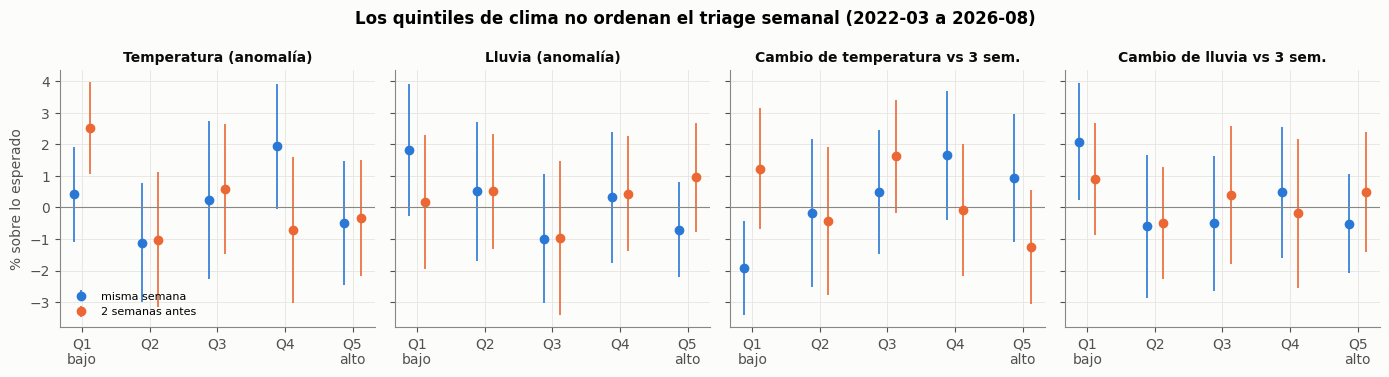

Diferencia Q5 − Q1 (puntos %):
                                 misma semana  2 semanas antes
Cambio de lluvia vs 3 sem.               -2.6             -0.4
Cambio de temperatura vs 3 sem.           2.9             -2.5
Lluvia (anomalía)                        -2.5              0.8
Temperatura (anomalía)                   -0.9             -2.8
Diferencia Q5 - Q1 con su intervalo del 95 % (puntos %):
  Temperatura (anomalía), misma semana: -0.9 [-3.4; +1.6]
  Temperatura (anomalía), 2 semanas antes: -2.8 [-5.2; -0.5]
  Lluvia (anomalía), misma semana: -2.5 [-5.1; +0.1]
  Lluvia (anomalía), 2 semanas antes: +0.8 [-2.0; +3.5]
  Cambio de temperatura vs 3 sem., misma semana: +2.9 [+0.3; +5.4]
  Cambio de temperatura vs 3 sem., 2 semanas antes: -2.5 [-5.1; +0.1]
  Cambio de lluvia vs 3 sem., misma semana: -2.6 [-5.0; -0.2]
  Cambio de lluvia vs 3 sem., 2 semanas antes: -0.4 [-3.0; +2.2]


In [16]:
vars_clima = ["Temperatura (anomalía)", "Lluvia (anomalía)", "Cambio de temperatura vs 3 sem.", "Cambio de lluvia vs 3 sem."]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
resumen = {}
for ax, v in zip(axes, vars_clima):
    for L, col, dx in [(0, AZUL, -.12), (2, NARANJA, .12)]:
        par = pd.concat([W.res_sin_estac, ext[v].shift(L)], axis=1).dropna()
        q = pd.qcut(par.iloc[:, 1], 5, labels=False)
        g = ((np.exp(par.iloc[:, 0]) - 1) * 100).groupby(q)
        m, e = g.mean(), 1.96 * g.std() / np.sqrt(g.count())
        ax.errorbar(m.index + dx, m.values, yerr=e.values, fmt="o", color=col, ms=6, lw=1.2, capsize=0,
                    label=f"misma semana" if L == 0 else "2 semanas antes")
        resumen[(v, L)] = m.iloc[-1] - m.iloc[0]
    ax.axhline(0, color=MUDO, lw=.8)
    ax.set_xticks(range(5), ["Q1\nbajo", "Q2", "Q3", "Q4", "Q5\nalto"])
    ax.set_title(v, fontsize=10)
axes[0].set_ylabel("% sobre lo esperado")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Los quintiles de clima no ordenan el triage semanal (2022-03 a 2026-08)", fontweight="bold")
plt.tight_layout(); plt.show()
print("Diferencia Q5 − Q1 (puntos %):")
print(pd.Series(resumen).unstack().rename(columns={0: "misma semana", 2: "2 semanas antes"}).round(1).to_string())

print("Diferencia Q5 - Q1 con su intervalo del 95 % (puntos %):")
for v in vars_clima:
    for L in (0, 2):
        par = pd.concat([W.res_sin_estac, ext[v].shift(L)], axis=1).dropna()
        q = pd.qcut(par.iloc[:, 1], 5, labels=False)
        g = ((np.exp(par.iloc[:, 0]) - 1) * 100).groupby(q)
        d = g.mean().iloc[-1] - g.mean().iloc[0]
        e = 1.96 * np.sqrt(g.var().iloc[-1] / g.count().iloc[-1] + g.var().iloc[0] / g.count().iloc[0])
        print(f"  {v}, {'misma semana' if L == 0 else '2 semanas antes'}: {d:+.1f} [{d - e:+.1f}; {d + e:+.1f}]")


## Lectura

**El triage total no cambia con el nivel semanal del clima de forma apreciable: las diferencias son de unos 3 puntos y sin un patrón coherente.**

- En las cuatro variables, la diferencia entre el quintil más alto y el más bajo queda dentro de ±2,9 puntos.
- De las 8 diferencias calculadas (4 variables, 2 rezagos), 3 tienen un intervalo del 95 % que no incluye el cero, y las tres por poco: la temperatura 2 semanas antes (−2,8 [−5,2; −0,5]), el cambio de temperatura de la misma semana (+2,9 [+0,3; +5,4]) y el cambio de lluvia de la misma semana (−2,6 [−5,0; −0,2]). Con 8 comparaciones se esperarían 0,4 por azar; tres es más, pero son efectos de 3 puntos o menos y sin signos coherentes entre sí.
- La **lluvia de la misma semana** es lo único con la dirección esperada: −2,5 puntos del quintil más seco al más lluvioso [−5,1; +0,1], con el intervalo apenas incluyendo el cero. Es coherente con que la lluvia desanime a salir, pero es pequeño.
- El **cambio de temperatura de la misma semana** es lo más parecido a una inclinación (sube de −1,9 % en el quintil más bajo a +0,9 % en el más alto), y es la misma celda que el mapa de la sección 3 marcaba con +0,15.

**Límites.**
- Es clima observado. Para pronosticar se necesitaría el clima pronosticado, y eso solo puede empeorar la señal.
- Solo el 34,7 % de los días tiene pluviómetro válido, así que la lluvia semanal lleva error; el pluviómetro de La Nubia reportó cero milímetros durante meses mientras llovía, y esos 199 días se tratan como ausentes.
- Un corte en quintiles no ve una relación condicionada, como el frío después de una sequía larga. Eso se mide en el apartado 10.2.

## 10.2 La transición

Episodio es el primer día de un cambio brusco, separado al menos 28 días del anterior: calentamiento o enfriamiento (la temperatura de la última semana frente a las tres anteriores, por encima o por debajo de una desviación para el mes) y paso de seco a lluvioso (lluvia de la última semana por encima de una desviación y de las tres anteriores por debajo de media desviación). Se compara la media del residuo diario, en tres ventanas posteriores, contra la semana previa al cambio, separando el total, los 0-4 años, los 65 años o más y los adultos de 15 a 44 años en día laboral. Son 36 comparaciones.

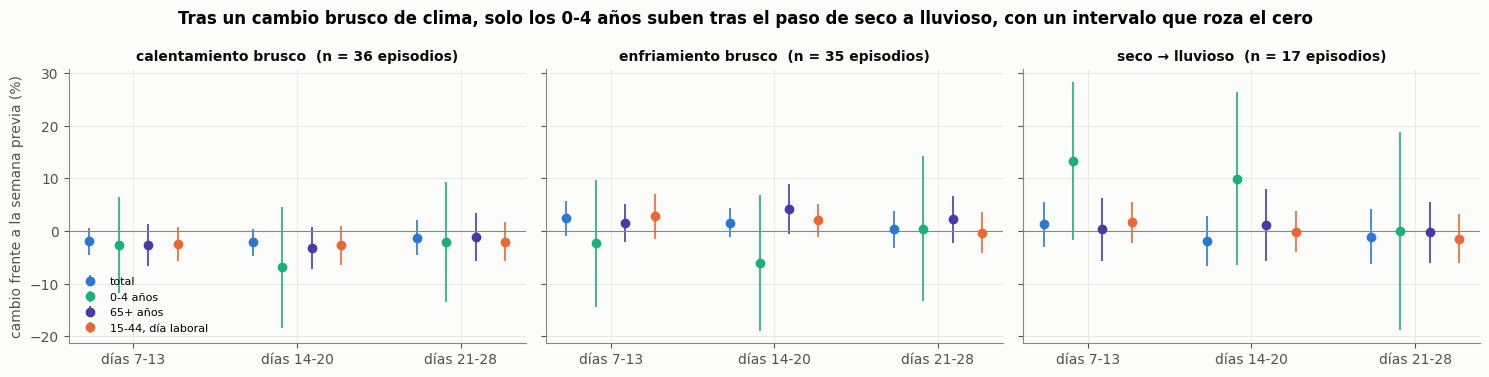

ventana                                     días 7-13    días 14-20  \
cambio               desenlace                                        
calentamiento brusco total                 -1.9 ± 2.5    -2.1 ± 2.6   
                     0-4 años              -2.6 ± 9.2   -6.9 ± 11.4   
                     65+ años              -2.7 ± 3.9    -3.2 ± 3.9   
                     15-44, día laboral    -2.5 ± 3.2    -2.7 ± 3.7   
enfriamiento brusco  total                 +2.4 ± 3.3    +1.6 ± 2.8   
                     0-4 años             -2.3 ± 12.0   -6.1 ± 12.8   
                     65+ años              +1.6 ± 3.6    +4.2 ± 4.7   
                     15-44, día laboral    +2.9 ± 4.3    +2.0 ± 3.2   
seco → lluvioso      total                 +1.3 ± 4.3    -1.9 ± 4.7   
                     0-4 años            +13.4 ± 15.0  +10.0 ± 16.4   
                     65+ años              +0.4 ± 5.9    +1.1 ± 6.9   
                     15-44, día laboral    +1.7 ± 3.9    -0.1 ± 3.9   

ventana                                   días 21-28  episodios  
cambio               desenlace                                   
calentamiento brusco total                -1.3 ± 3.3         36  
                     0-4 años            -2.1 ± 11.3         36  
                     65+ años             -1.1 ± 4.5         36  
                     15-44, día laboral   -2.0 ± 3.7         36  
enfriamiento brusco  total                +0.3 ± 3.5         35  
                     0-4 años            +0.5 ± 13.7         35  
                     65+ años             +2.3 ± 4.5         35  
                     15-44, día laboral   -0.3 ± 3.9         35  
seco → lluvioso      total                -1.0 ± 5.1         17  
                     0-4 años            +0.1 ± 18.8         17  
                     65+ años             -0.3 ± 5.9         17  
                     15-44, día laboral   -1.5 ± 4.6         17

In [17]:
# ---------- transiciones de clima: efecto en las semanas siguientes al cambio, por subgrupo
cl_d = clima.reindex(dias)
t = cl_d.temp_media_consenso
dT = t.rolling(7).mean() - t.shift(7).rolling(21).mean()
zT = (dT - dT.groupby(dT.index.month).transform("mean")) / dT.groupby(dT.index.month).transform("std")
pr = cl_d.precip_consenso_mm
p7, p21 = pr.rolling(7).sum(), pr.shift(7).rolling(21).sum() / 3
z7 = (p7 - p7.groupby(p7.index.month).transform("mean")) / p7.groupby(p7.index.month).transform("std")
z21 = (p21 - p21.groupby(p21.index.month).transform("mean")) / p21.groupby(p21.index.month).transform("std")
senales = {"calentamiento brusco": zT >= 1, "enfriamiento brusco": zT <= -1, "seco → lluvioso": (z7 >= 1) & (z21 <= -.5)}

def episodios(senal, sep=28):
    ini_, ult = [], None
    for d in senal[senal.fillna(False)].index:
        if ult is None or (d - ult).days >= sep:
            ini_.append(d); ult = d
    return [d for d in ini_ if pd.Timestamp(INI) <= d <= pd.Timestamp(FIN) - pd.Timedelta(days=28)]
EP = {k: episodios(v) for k, v in senales.items()}
salidas = {"total": RB.total, "0-4 años": RB["0-4"], "65+ años": RB["65+"], "15-44, día laboral": RB["15-44"].where(laboral)}
VENT = {"días 7-13": (7, 13), "días 14-20": (14, 20), "días 21-28": (21, 28)}
filas = []
for ne, fechas in EP.items():
    for ns, serie in salidas.items():
        difs = {k: [] for k in VENT}
        for f in fechas:
            base = serie.loc[f - pd.Timedelta(days=7): f - pd.Timedelta(days=1)].mean()
            for k, (a, b) in VENT.items():
                difs[k].append(serie.loc[f + pd.Timedelta(days=a): f + pd.Timedelta(days=b)].mean() - base)
        for k, v in difs.items():
            v = pd.Series(v).dropna()
            filas.append({"cambio": ne, "desenlace": ns, "ventana": k, "efecto %": pct(v.mean()),
                          "ic": 1.96 * v.std() / np.sqrt(len(v)) * 100, "n": len(v)})
T41 = pd.DataFrame(filas)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
colores = [AZUL, AQUA, VIOLETA, NARANJA]
for ax, (ne, g) in zip(axes, T41.groupby("cambio", sort=False)):
    for j, (ns, h) in enumerate(g.groupby("desenlace", sort=False)):
        x = np.arange(3) + (j - 1.5) * .18
        ax.errorbar(x, h["efecto %"], yerr=h["ic"], fmt="o", color=colores[j], ms=6, lw=1.2, label=ns)
    ax.axhline(0, color=MUDO, lw=.8); ax.set_xticks(range(3), list(VENT)); ax.set_title(f"{ne}  (n = {int(g.n.max())} episodios)", fontsize=10)
axes[0].set_ylabel("cambio frente a la semana previa (%)"); axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Tras un cambio brusco de clima, solo los 0-4 años suben tras el paso de seco a lluvioso, con un intervalo que roza el cero", fontweight="bold")
plt.tight_layout(); plt.show()
T41.assign(celda=T41.apply(lambda r: f"{r['efecto %']:+.1f} ± {r.ic:.1f}", axis=1)).pivot_table(
    index=["cambio", "desenlace"], columns="ventana", values="celda", aggfunc="first", sort=False
).assign(episodios=T41.groupby(["cambio", "desenlace"], sort=False).n.max())

## Lectura

**Tras un cambio brusco, el único efecto que se aparta del cero es el de los menores de 5 años al pasar de seco a lluvioso, y su intervalo roza el cero.**

| | días 7-13 | días 14-20 | días 21-28 | episodios |
|---|---|---|---|---|
| **seco → lluvioso, 0-4 años** | **+13,4 ± 15,0** | +10,0 ± 16,4 | +0,1 ± 18,8 | 17 |
| enfriamiento, 65+ | +1,6 ± 3,6 | **+4,2 ± 4,7** | +2,3 ± 4,5 | 35 |
| enfriamiento, 15-44 en día laboral | **+2,9 ± 4,3** | +2,0 ± 3,2 | −0,3 ± 3,9 | 35 |
| enfriamiento, total | +2,4 ± 3,3 | +1,6 ± 2,8 | +0,3 ± 3,5 | 35 |
| calentamiento, total | −1,9 ± 2,5 | −2,1 ± 2,6 | −1,3 ± 3,3 | 36 |

- **Los menores de 5 años suben entre 10 y 13 % una o dos semanas después de pasar de seco a lluvioso, y el efecto se apaga a la cuarta semana.** Tiene la forma de una incubación: no pasa nada el mismo día, sube después y se desvanece. Pero el intervalo de la primera ventana incluye el cero y son 17 episodios. Una falla del pluviómetro de La Nubia fabricaba sequías falsas y, con ellas, episodios de paso a lluvia; con esos 199 días tratados como ausentes, la señal es una pista y no un hallazgo.
- **El enfriamiento sube algo a los mayores y a los adultos en día laboral, y el calentamiento baja el total.** Los signos son coherentes en casi todas las ventanas, pero cada intervalo por separado cruza el cero.
- **En el total, el efecto es de ±2 %**, pequeño frente al ruido diario del 12 %. Para el pronóstico del total, estas variables ayudarían poco solas.

**Lectura por mecanismo.** El reloj es de una a tres semanas, el gatillo es la transición y no el nivel, la condición es el día laboral y el subgrupo son los menores y los mayores. Es la lectura que el mapa de la sección 3 no podía hacer, y es la que mejor corresponde al mecanismo planteado, aunque con la evidencia actual no se sostiene como hallazgo.

**Límites.**
- Con 36 comparaciones, alguna saldría «significativa» por azar; el resultado de los menores necesita confirmarse fuera de muestra.
- Los episodios se definen sobre el clima observado y el consenso de varias fuentes, y el consenso sobreestima los días con lluvia: en los días con pluviómetro válido marca lluvia el 66,0 % de los días, y el pluviómetro el 43,0 % (`calendarios/docs/CLIMA.md`).
- El hospital ve diluido lo respiratorio dentro del total, de modo que un efecto de los menores pesa poco en el conteo general.

---
# 11. Catástrofes

**Mecanismo.** Reloj de días a semanas. Gatillo: el evento mismo. Condición: que afecte al acceso o a la oferta del hospital más que a su demanda. Subgrupo esperado: el que depende de la movilidad y de la agenda programada.

Residuo diario en los 14 días antes y los 21 después de cada desastre **municipal o institucional con fecha confirmada** del calendario manual. Son pocos, y el calendario de desastres es el más pobre de los calendarios externos.

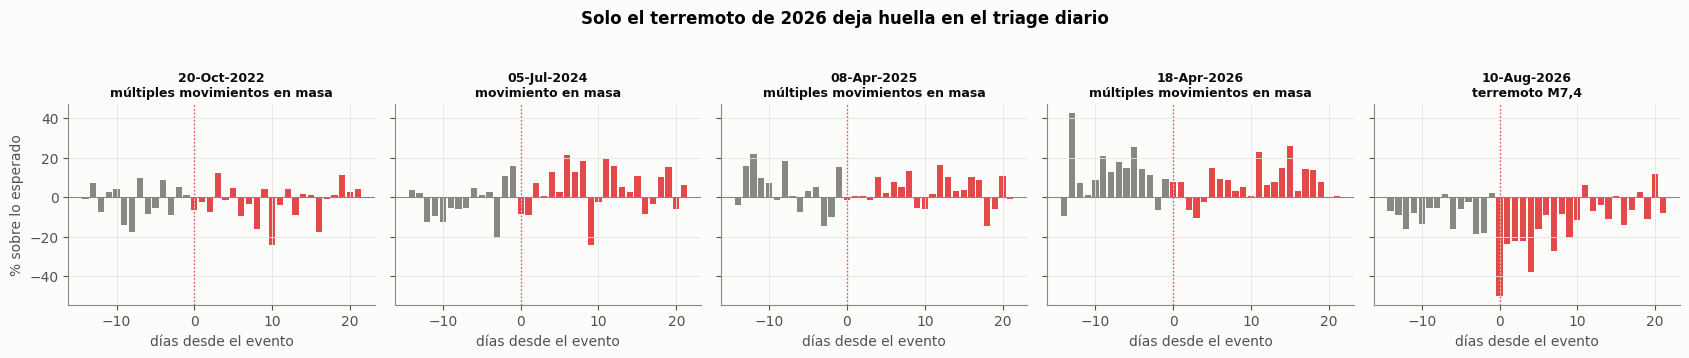

terremoto del 10-08-2026: día 0 -50 %, media de los días 0 a 13 -18.2 %


In [18]:
ev = desastres[desastres.ambito.isin(["municipal", "institucional"])
               & ~desastres.calidad_dato.isin(["pendiente_verificacion", "fecha_aproximada"])]
ev = ev.drop_duplicates("fecha_inicio")
fig, axes = plt.subplots(1, len(ev), figsize=(3.4 * len(ev), 3.4), sharey=True)
axes = np.atleast_1d(axes)
filas = []
for ax, (_, e) in zip(axes, ev.iterrows()):
    t0 = pd.Timestamp(e.fecha_inicio)
    k = range(-14, 22)
    s = D.res.reindex([t0 + pd.Timedelta(days=i) for i in k]); s.index = list(k)
    p = (np.exp(s) - 1) * 100
    ax.axvline(0, color=ROJO, lw=1, ls=":"); ax.axhline(0, color=MUDO, lw=.8)
    ax.bar(p.index, p.values, color=[ROJO if i >= 0 else MUDO for i in p.index], width=.8)
    ax.set_title(f"{t0:%d-%b-%Y}\n{e.subtipo.replace('_', ' ').replace('multiples', 'múltiples').replace('M7.4', 'M7,4')[:30]}", fontsize=9)
    ax.set_xlabel("días desde el evento")
    filas.append({"fecha": f"{t0:%Y-%m-%d}", "evento": e.subtipo, "14 días antes": p.loc[-14:-1].mean().round(1),
                  "7 días después": p.loc[0:6].mean().round(1), "8-21 días después": p.loc[7:21].mean().round(1)})
axes[0].set_ylabel("% sobre lo esperado")
fig.suptitle("Solo el terremoto de 2026 deja huella en el triage diario", fontweight="bold", y=1.04)
plt.tight_layout(); plt.show()
pd.DataFrame(filas)

t0 = pd.Timestamp("2026-08-10")
sq = (np.exp(D.res.reindex([t0 + pd.Timedelta(days=i) for i in range(0, 14)])) - 1) * 100
print(f"terremoto del {t0:%d-%m-%Y}: día 0 {sq.iloc[0]:.0f} %, media de los días 0 a 13 {sq.mean():.1f} %")


## Lectura

- **Los deslizamientos no dejan huella en el triage.** Los 7 días posteriores quedan entre −1,5 y +3,9 %, dentro del ruido diario (±12 %). Tiene sentido: afectan a pocas personas y sobre todo a las vías.
- **El terremoto del 10 de agosto de 2026 sí, y hacia abajo.** El día del sismo, −50 %; en los primeros 7 días, −26,0 %; en los días 0 a 13, −18,2 % de media; y de los días 7 a 21, −7,2 %. Los 14 días anteriores ya estaban en −8,7 %, en parte por la caída del volumen de Nueva EPS en julio de 2026, de modo que lo atribuible al sismo es la diferencia. Una catástrofe grande reduce el triage registrado de este hospital.

  Caben varias explicaciones y los datos no distinguen entre ellas:
  - que el servicio activara una expansión hospitalaria y cancelara la consulta programada;
  - que la gente evitara los edificios;
  - que hubiera vías cerradas;
  - o que el registro se hiciera de otra manera durante la emergencia.

**Límite serio: es un solo evento.** El calendario de desastres tiene 5 eventos municipales con fecha confirmada, y cuatro de ellos son deslizamientos. Con un evento no se puede decir cuánto de la caída es del terremoto, y no hay base para generalizar a otras catástrofes.

---
# 12. Conclusiones por mecanismo

Cada factor se resume con su reloj, su gatillo, su condición y su subgrupo, y con el estado de la evidencia que dejan estos análisis.

| Factor | Reloj | Gatillo | Condición | Subgrupo | Qué se midió | Estado |
|---|---|---|---|---|---|---|
| **Red de salud (Nueva EPS)** | meses, en escalones | cambio de situación de la aseguradora | siempre | el asegurador | semanas de −15 a −32 % desde noviembre de 2025 (sección 2); −38 % del volumen de Nueva EPS en 2026 (cuaderno 07) | efecto más grande del cuaderno, institucional |
| **Feria** | 0 a 5 días | inicio de la aglomeración | cae sobre el regreso de vacaciones | SOAT, particulares | total +7,3 ± 8,5 % frente a +2,7 ± 2,3 %; SOAT +36,9 ± 5,5 % frente a +12,5 ± 8,5 % | huella en el subgrupo; en el total no se separa del calendario |
| **Noches festivas** | horas a 3 días | noche de fiesta y día que le sigue | día no laboral | madrugada, particulares | madrugada +31 a +44 %, particulares +74 % el 31, día completo −24 a −40 % | efecto en el subgrupo, fecha conocida |
| **Arranque de enero** | 0 a 5 días | día después de Año Nuevo, regreso, Feria | primera quincena de enero | total | 3 de enero +14,0 % | no se separa de la fecha |
| **Mitad del año** | semanas | temporada | receso escolar, temporada respiratoria | total | vacaciones +6,4 % (control A) frente a +1,7 % (control B) | efecto en el nivel, no se separa de la temporada |
| **Clima, nivel** | misma semana | nivel | — | total | −2,5 puntos con lluvia, dentro de ±2,9 | sin inclinación visible |
| **Clima, transición** | 1 a 3 semanas | cambio brusco | día laboral | 0-4 años, 65+ | seco a lluvioso en 0-4: +13,4 ± 15,0 % | pista; no se distingue del cero |
| **Terremoto** | días a semanas | el evento | acceso y oferta del hospital | total | −26,0 % la primera semana, −18,2 % de media en dos | un solo evento |

## Conclusiones

1. **«Casi nada se mueve con el total» describe a un método, no al hospital.** El mapa de correlaciones sobre un residuo sin estacionalidad solo detecta efectos semanales de 5 a 10 % o más; los factores externos que se conocen actúan en pocos días y en subgrupos pequeños, y por eso no aparecen allí.
2. **Los factores festivos y sociales dejan huella, pero en el subgrupo y con su propio reloj**: la Feria en el SOAT y los particulares, las noches de fiesta en la madrugada y en los particulares, el arranque de enero en los días 2 a 4. En el total se diluyen.
3. **El nivel del año lo mueve la red de salud, no el clima ni el calendario**, y esa capa tiene que ir en el modelo antes que cualquier variable externa.
4. **El clima como transición muestra una pista en los menores de 5 años** a una o dos semanas, que con la evidencia actual no se distingue del cero. El clima de nivel no muestra pendiente.
5. **Una catástrofe grande reduce el conteo registrado**, y con un solo evento no se puede decir más.

## Límites del análisis

- **No se puede separar la Feria del regreso de vacaciones y de Año Nuevo en el total**, porque cae siempre en las mismas fechas. Solo la huella en el subgrupo la distingue.
- **No se puede separar las vacaciones de mitad de año de la temporada respiratoria y de las fiestas de los pueblos**, que caen juntas en los cinco años disponibles.
- **El terremoto es un solo evento**, y su efecto se mezcla con el desplome de Nueva EPS en julio de 2026.
- **La vigilancia del SIVIGILA llega solo hasta 2025**, así que el mapa cubre unas 200 semanas, y su total de consultas mezcla consulta externa con urgencias.
- **El clima usado es observado**: para pronosticar se tendrá que usar el pronosticado, que solo puede empeorar la señal.
- **Son análisis exploratorios con muchas comparaciones.** Ninguna asociación de este cuaderno es un hallazgo hasta fijarse de antemano y probarse fuera de muestra, con origen rodante, contra el control de calendario.